# Quantitative Research: NASDAQ Futures (NQ) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (NQ) from MongoDB, using reusable functions from `utils.py`. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `nq_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

## IMPORTS AND CONFIG

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')


utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from utils import (
    load_data_from_mongo,
    resample_timeframes,
    analyze_timeframe_detailed,
)

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")

Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## LOAD DATA FROM MONGODB 

In [2]:
df_raw = load_data_from_mongo('nq_15min')

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} → {df_raw.index.max()}")
df_raw.head()

Raw data shape: (397830, 5)
Date range: 2009-09-27 18:00:00 → 2026-08-28 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1697.00,1701.00,1696.00,1699.25,596
2009-09-27 18:15:00,1699.25,1700.00,1699.25,1699.50,25
2009-09-27 18:30:00,1699.75,1700.00,1699.50,1699.50,15
2009-09-27 18:45:00,1699.50,1699.50,1699.25,1699.50,11
2009-09-27 19:00:00,1699.50,1699.75,1694.00,1696.00,584


## DATA QUALITY CHECK

Comparison with Yahoo Finance (daily closes):
        Mongo_close   Yahoo_close     diff_pct
count   4256.000000   4256.000000  4256.000000
mean    9181.616541   9176.299816     0.029074
std     7185.379846   7177.716105     0.469510
min     1662.000000   1662.250000    -6.709778
25%     3482.000000   3479.687500    -0.121580
50%     6635.500000   6639.750000     0.021847
75%    13700.312500  13689.812500     0.174501
max    30653.000000  30712.750000     3.113709


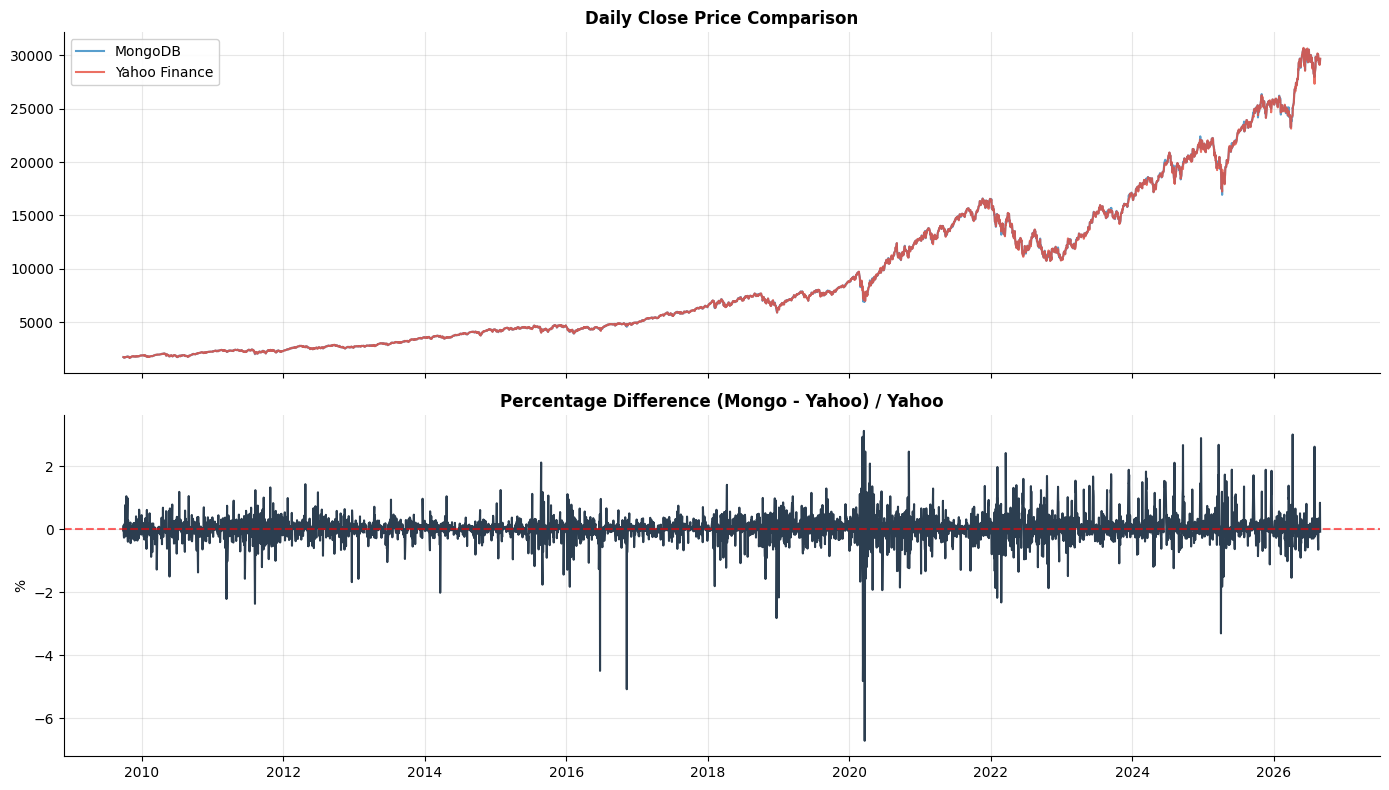

Mean difference: 0.0291%


In [3]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

nq_yahoo = yf.download('NQ=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
nq_yahoo = nq_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
nq_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(nq_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
nq_yahoo_aligned = nq_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': nq_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

## RESAMPLE TO MULTIPLE TIMEFRAMES

In [4]:
timeframes = resample_timeframes(df_raw)

print("Timeframes created:")
for name, df in timeframes.items():
    print(f"{name}: {len(df)}")

Timeframes created:
15min: 397830
1H: 101228
4H: 27027
1D: 5262


## ROLL DIAGNOSTIC — outliers vs ES expiration calendar

In [5]:

# --- 1. Isolate days with significant Mongo vs Yahoo discrepancy ---
THRESHOLD_PCT = 1.0  # adjust to be more/less strict

outliers = comparison[comparison['diff_pct'].abs() > THRESHOLD_PCT].copy()
outliers = outliers.sort_values('diff_pct')

print(f"Days with |diff_pct| > {THRESHOLD_PCT}%: {len(outliers)}")
print(outliers[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 2. Generate approximate ES roll calendar (H, M, U, Z contracts) ---
expiry_months = [3, 6, 9, 12]  # March, June, September, December
years = range(df_daily.index.min().year, df_daily.index.max().year + 2)

third_fridays = []
for y in years:
    for m in expiry_months:
        fridays = pd.date_range(f'{y}-{m}-01', f'{y}-{m}-28', freq='W-FRI')
        if len(fridays) >= 3:
            third_fridays.append(fridays[2])

roll_dates = pd.Series(sorted(third_fridays))
ROLL_WINDOW_DAYS = 10  # business days before expiry when the roll typically happens

# --- 3. Cross-check each outlier against the nearest roll window ---
def nearest_roll_distance(date):
    diffs = (roll_dates - date).dt.days
    # we care about the window [-ROLL_WINDOW_DAYS, 0] before expiry
    candidates = diffs[(diffs >= 0) & (diffs <= ROLL_WINDOW_DAYS)]
    return candidates.min() if len(candidates) > 0 else None

outliers['days_to_next_expiry'] = [nearest_roll_distance(d) for d in outliers.index]
outliers['is_roll_window'] = outliers['days_to_next_expiry'].notna()

print("\nOutliers cross-checked against roll calendar:")
print(outliers[['diff_pct', 'days_to_next_expiry', 'is_roll_window']])

pct_explained = outliers['is_roll_window'].mean() * 100
print(f"\n% of outliers explained by roll window: {pct_explained:.1f}%")

# --- 4. Roll flag applied to the FULL daily index (not just outliers) ---
# we'll reuse this later to exclude/flag days in the gap% calculation
df_daily['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily.index
]
print(f"\nTotal days flagged as roll window in the full series: {df_daily['is_roll_window'].sum()}")

Days with |diff_pct| > 1.0%: 196
            Mongo_close   Yahoo_close  diff_pct
2020-03-20      6920.25   7417.979980 -6.709778
2016-11-08      4558.50   4802.250000 -5.075746
2020-03-11      7618.00   8003.500000 -4.816643
2016-06-23      4262.00   4462.500000 -4.492997
2020-03-18      6911.50   7225.250000 -4.342410
...                 ...           ...       ...
2025-03-21     19970.75  19450.810547  2.673099
2024-12-20     21552.50  20947.980469  2.885813
2020-03-09      8184.25   7951.500000  2.927121
2026-04-07     25102.00  24371.000000  2.999467
2020-03-16      7277.25   7057.500000  3.113709

[196 rows x 3 columns]

Outliers cross-checked against roll calendar:
            diff_pct  days_to_next_expiry  is_roll_window
2020-03-20 -6.709778                  0.0            True
2016-11-08 -5.075746                  NaN           False
2020-03-11 -4.816643                  9.0            True
2016-06-23 -4.492997                  NaN           False
2020-03-18 -4.342410          

## SESSION-DATE DIAGNOSTIC — calendar-day vs trading-session boundary

In [6]:

SESSION_START_HOUR = 18

def to_session_date(timestamp):
    if timestamp.hour >= SESSION_START_HOUR:
        return (timestamp + pd.Timedelta(days=1)).normalize()
    return timestamp.normalize()

df_raw_sess = df_raw.copy()
df_raw_sess['session_date'] = [to_session_date(ts) for ts in df_raw_sess.index]

# --- 2. Rebuild daily bars grouped by session_date instead of calendar day ---
df_daily_session = df_raw_sess.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_session.index.name = 'time'

# --- 3. Re-run the Mongo vs Yahoo comparison using session-based daily bars ---
common_idx_sess = df_daily_session.index.intersection(nq_yahoo.index)
df_daily_session_aligned = df_daily_session.loc[common_idx_sess]
nq_yahoo_aligned_sess = nq_yahoo.loc[common_idx_sess]

comparison_session = pd.DataFrame({
    'Mongo_close': df_daily_session_aligned['close'],
    'Yahoo_close': nq_yahoo_aligned_sess['close']
})
comparison_session['diff_pct'] = (
    (comparison_session['Mongo_close'] - comparison_session['Yahoo_close'])
    / comparison_session['Yahoo_close'] * 100
)

print("Comparison using SESSION-DATE daily bars:")
print(comparison_session.describe())

# --- 4. Compare outlier count before vs after the fix ---
outliers_session = comparison_session[comparison_session['diff_pct'].abs() > THRESHOLD_PCT]
print(f"\nDays with |diff_pct| > {THRESHOLD_PCT}% — calendar-day method: {len(outliers)}")
print(f"Days with |diff_pct| > {THRESHOLD_PCT}% — session-date method:  {len(outliers_session)}")

# --- 5. Check specifically whether the previously "unexplained" dates improve ---
unexplained_dates = outliers[~outliers['is_roll_window']].index
check_unexplained = comparison_session.loc[
    comparison_session.index.intersection(unexplained_dates)
]
print("\nPreviously unexplained outliers, re-measured with session-date bars:")
print(check_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Comparison using SESSION-DATE daily bars:
        Mongo_close   Yahoo_close     diff_pct
count   4256.000000   4256.000000  4256.000000
mean    9180.669349   9176.299816     0.025268
std     7183.752521   7177.716105     0.328505
min     1662.000000   1662.250000    -6.709778
25%     3477.250000   3479.687500    -0.056025
50%     6637.750000   6639.750000     0.012549
75%    13700.125000  13689.812500     0.080152
max    30813.250000  30712.750000     3.576043

Days with |diff_pct| > 1.0% — calendar-day method: 196
Days with |diff_pct| > 1.0% — session-date method:  122

Previously unexplained outliers, re-measured with session-date bars:
            Mongo_close  Yahoo_close  diff_pct
2009-10-13      1742.50      1726.75  0.912118
2010-05-24      1806.75      1812.50 -0.317241
2010-07-13      1862.00      1842.50  1.058345
2010-08-31      1774.75      1766.50  0.467025
2010-10-18      2065.25      2094.50 -1.396515
...                 ...          ...       ...
2025-10-30     26149.25 

## COMBINED DIAGNOSTIC — roll + session-date, checking what's left

In [7]:

# --- 1. Re-run outlier detection on the session-date comparison ---
outliers_session_full = comparison_session[
    comparison_session['diff_pct'].abs() > THRESHOLD_PCT
].copy()
outliers_session_full = outliers_session_full.sort_values('diff_pct')

# --- 2. Cross-check these against the roll calendar (reuse nearest_roll_distance) ---
outliers_session_full['days_to_next_expiry'] = [
    nearest_roll_distance(d) for d in outliers_session_full.index
]
outliers_session_full['is_roll_window'] = outliers_session_full['days_to_next_expiry'].notna()

pct_explained_combined = outliers_session_full['is_roll_window'].mean() * 100
print(f"Outliers remaining after session-date fix: {len(outliers_session_full)}")
print(f"% of THOSE explained by roll window: {pct_explained_combined:.1f}%")

# --- 3. Isolate what's still unexplained by EITHER fix ---
still_unexplained = outliers_session_full[~outliers_session_full['is_roll_window']]
still_unexplained = still_unexplained.sort_values('diff_pct', key=abs, ascending=False)

print(f"\nStill unexplained after both fixes: {len(still_unexplained)}")
print(still_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 4. Flag the worst offenders for manual inspection (likely source-data errors) ---
SEVERE_THRESHOLD = 1.5
severe_unexplained = still_unexplained[still_unexplained['diff_pct'].abs() > SEVERE_THRESHOLD]
print(f"\nSevere unexplained cases (|diff_pct| > {SEVERE_THRESHOLD}%): {len(severe_unexplained)}")
print(severe_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Outliers remaining after session-date fix: 122
% of THOSE explained by roll window: 63.9%

Still unexplained after both fixes: 44
            Mongo_close  Yahoo_close  diff_pct
2026-06-05     30064.50     29026.50  3.576043
2025-04-02     19152.25     19758.00 -3.065847
2026-08-04     29208.50     29863.50 -2.193313
2022-02-03     14803.75     14492.25  2.149425
2026-07-29     27906.75     27342.00  2.065504
2026-07-02     30160.50     29556.00  2.045270
2026-07-27     28682.25     28190.00  1.746187
2019-01-02      6261.25      6371.00 -1.722650
2022-02-02     14863.25     15114.50 -1.662311
2026-06-30     30016.75     30523.50 -1.660196
2026-06-25     30193.25     29724.75  1.576128
2022-01-25     13922.25     14140.75 -1.545180
2022-04-26     12815.50     13016.00 -1.540412
2026-07-30     27815.75     28237.75 -1.494453
2026-08-03     28460.25     28891.75 -1.493506
2022-07-28     12924.25     12737.50  1.466143
2026-05-08     28916.50     29332.50 -1.418222
2024-04-25     17816.50 

# FINAL CLEAN DAILY SERIES — session-date + roll flag combined

In [8]:

df_raw_clean = df_raw.copy()
df_raw_clean['session_date'] = [to_session_date(ts) for ts in df_raw_clean.index]

df_daily_clean = df_raw_clean.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_clean.index.name = 'time'

df_daily_clean['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily_clean.index
]

SEVERE_UNEXPLAINED_DATES = pd.to_datetime([
    '2025-04-02', '2026-06-05', '2026-07-29', '2020-04-16'
])
df_daily_clean['is_flagged_exception'] = df_daily_clean.index.isin(SEVERE_UNEXPLAINED_DATES)

print(f"Total daily bars: {len(df_daily_clean)}")
print(f"Bars in roll window: {df_daily_clean['is_roll_window'].sum()}")
print(f"Bars flagged as unresolved exceptions: {df_daily_clean['is_flagged_exception'].sum()}")

df_daily_clean.head()

Total daily bars: 4386
Bars in roll window: 604
Bars flagged as unresolved exceptions: 4


,open,high,low,close,volume,is_roll_window,is_flagged_exception
time,,,,,,,
2009-09-28,1697.00,1732.50,1688.00,1722.75,251779,False,False
2009-09-29,1722.25,1730.75,1706.75,1715.25,276954,False,False
2009-09-30,1715.00,1730.00,1688.75,1714.00,429696,False,False
2009-10-01,1714.25,1726.75,1663.75,1668.25,402271,False,False
2009-10-02,1668.75,1674.75,1649.75,1662.00,366062,False,False


## GAP% CALCULATION

In [9]:
# --- 1. PRE-CLOSE reference price: last bar at 16:30 ET for each session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
df_1630['session_date'] = [to_session_date(ts) for ts in df_1630.index]

close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

# --- 2. OPEN reference price: first bar of the session (18:00) ---
open_1800 = df_daily_clean['open']  # already the session open (18:00 bar)

# --- 3. Align: session D's open is compared against D-1's close_1630 ---
gap_df = pd.DataFrame({'open_1800': open_1800})
gap_df['prev_close_1630'] = close_1630.shift(1).reindex(gap_df.index)

gap_df['gap_pct_adj'] = (
    (gap_df['open_1800'] - gap_df['prev_close_1630']) / gap_df['prev_close_1630'] * 100
)

# --- 4. Attach existing flags ---
gap_df['is_roll_window'] = df_daily_clean['is_roll_window']
gap_df['is_flagged_exception'] = df_daily_clean['is_flagged_exception']
gap_df['dow'] = gap_df.index.day_name()

n_before = len(gap_df)
df_gaps_adj = gap_df.dropna(subset=['gap_pct_adj']).copy()
n_dropped = n_before - len(df_gaps_adj)
print(f"Sessions dropped due to missing 16:30 reference bar: {n_dropped}")

roll_gaps_adj = df_gaps_adj[df_gaps_adj['is_roll_window']]['gap_pct_adj']
normal_gaps_adj = df_gaps_adj[~df_gaps_adj['is_roll_window']]['gap_pct_adj']

print("\nADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS")
print(normal_gaps_adj.describe())
print(f"Mean |gap| adjusted: {normal_gaps_adj.abs().mean():.4f}%")

# --- 5. Comparison against old gap — guarded, in case 'normal_gaps' isn't
# defined in this kernel session (e.g. kernel was restarted) ---
if 'normal_gaps' in dir():
    print("\nQuick comparison against the old gap (17:45->18:00):")
    print(f"  Old      — std: {normal_gaps.std():.4f}%, mean|gap|: {normal_gaps.abs().mean():.4f}%")
    print(f"  Adjusted — std: {normal_gaps_adj.std():.4f}%, mean|gap|: {normal_gaps_adj.abs().mean():.4f}%")
else:
    print("\n[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.")

# --- 6. Diagnostic: which sessions are missing the 16:30 bar? ---
dropped_sessions = gap_df[gap_df['gap_pct_adj'].isna()].index
print(f"\nExamples of sessions without a 16:30 bar ({len(dropped_sessions)} total):")
print(dropped_sessions[:20])

print("\nDropped sessions by year:")
print(dropped_sessions.year.value_counts().sort_index())

Sessions dropped due to missing 16:30 reference bar: 322

ADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS
count    3488.000000
mean       -0.009477
std         0.348923
min        -4.408487
25%        -0.044193
50%         0.000000
75%         0.046068
max         3.363672
Name: gap_pct_adj, dtype: float64
Mean |gap| adjusted: 0.1405%

[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.

Examples of sessions without a 16:30 bar (322 total):
DatetimeIndex(['2009-09-28', '2009-10-02', '2009-10-09', '2009-10-16',
               '2009-10-23', '2009-10-30', '2009-11-06', '2009-11-13',
               '2009-11-20', '2009-11-26', '2009-11-27', '2009-12-04',
               '2009-12-11', '2009-12-18', '2009-12-24', '2009-12-31',
               '2010-01-08', '2010-01-15', '2010-01-18', '2010-01-22'],
              dtype='datetime64[us]', name='time', freq=None)

Dropped sessions by year:
time
2009    16
2010    58
2011    58
2012    56
2013 

## GAP% DISTRIBUTION — descriptive statistics

ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)
count    3488.000000
mean       -0.009477
std         0.348923
min        -4.408487
25%        -0.044193
50%         0.000000
75%         0.046068
max         3.363672
Name: gap_pct_adj, dtype: float64
Mean |gap|: 0.1405%
Skew: -2.0415
Excess kurtosis: 33.6632

Up gaps: 1713 (49.1%), mean 0.1334%
Down gaps: 1680 (48.2%), mean -0.1557%

  percentile  abs_gap_pct
         50     0.045621
         75     0.109831
         90     0.307700
         95     0.614676
         99     1.725229


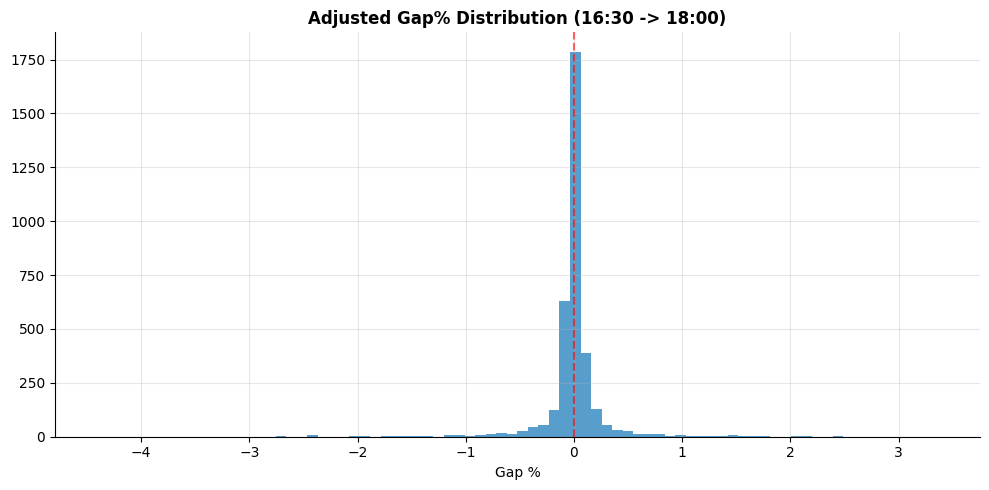

In [10]:
# --- Gap size distribution — descriptive only ---
print("ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)")
print(normal_gaps_adj.describe())
print(f"Mean |gap|: {normal_gaps_adj.abs().mean():.4f}%")
print(f"Skew: {normal_gaps_adj.skew():.4f}")
print(f"Excess kurtosis: {normal_gaps_adj.kurt():.4f}")

# Direction split — how often gaps are up vs down, and by how much
up_gaps = normal_gaps_adj[normal_gaps_adj > 0]
down_gaps = normal_gaps_adj[normal_gaps_adj < 0]
print(f"\nUp gaps: {len(up_gaps)} ({len(up_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {up_gaps.mean():.4f}%")
print(f"Down gaps: {len(down_gaps)} ({len(down_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {down_gaps.mean():.4f}%")

# Percentile table — where the mass of the distribution sits
percentiles = [50, 75, 90, 95, 99]
pct_table = pd.DataFrame({
    'percentile': percentiles,
    'abs_gap_pct': [normal_gaps_adj.abs().quantile(p/100) for p in percentiles]
})
print("\n", pct_table.to_string(index=False))

# Optional: quick histogram, same visual style as the rest of the notebook
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(normal_gaps_adj, bins=80, color='#2E86C1', alpha=0.8)
ax.axvline(0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Adjusted Gap% Distribution (16:30 -> 18:00)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## GAP% SEASONALITY — day of week

Gap by day of week:
               mean       std  count
dow                                 
Monday    -0.022312  0.681847  794.0
Tuesday    0.005648  0.258872  872.0
Wednesday -0.000802  0.189883  868.0
Thursday  -0.008566  0.158719  849.0
Friday     0.004483  0.174114  681.0
Sunday          NaN       NaN    NaN

No sessions flagged as Sunday — check to_session_date() logic


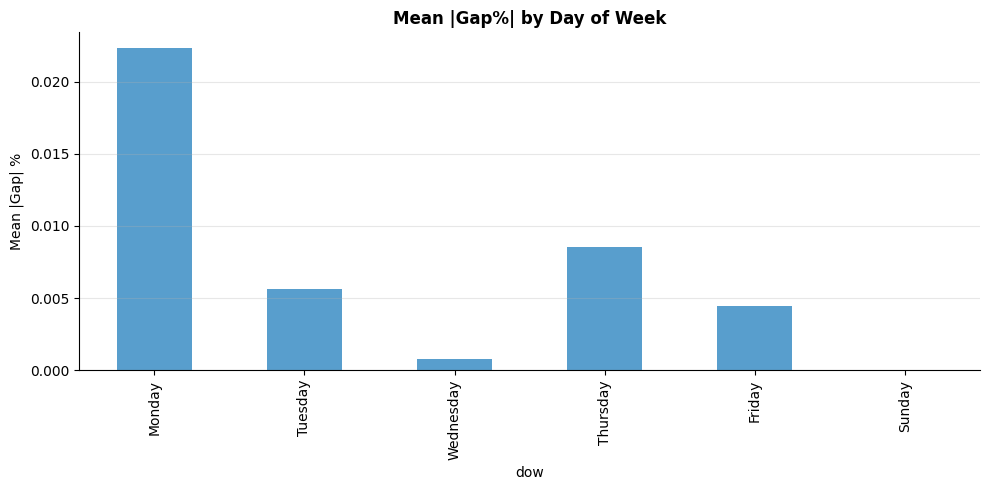

In [11]:
gap_by_dow = df_gaps_adj.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
gap_by_dow = gap_by_dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'])
print("Gap by day of week:")
print(gap_by_dow)

if 'Sunday' in df_gaps_adj['dow'].values:
    print("\nWeekend gap (Sunday reopen):")
    print(df_gaps_adj[df_gaps_adj['dow'] == 'Sunday']['gap_pct_adj'].describe())
else:
    print("\nNo sessions flagged as Sunday — check to_session_date() logic")

fig, ax = plt.subplots(figsize=(10, 5))
gap_by_dow['mean'].abs().plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8)
ax.set_title('Mean |Gap%| by Day of Week', fontweight='bold')
ax.set_ylabel('Mean |Gap| %')
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## DATA COMPLETENESS CHECK: BARS PER SESSION

In [12]:
# --- Data completeness check: bars per session by year ---
session_dates = [to_session_date(ts) for ts in df_raw.index]
bars_per_session = pd.Series(session_dates).value_counts().sort_index()
bars_per_session = bars_per_session.to_frame('n_bars')
bars_per_session['year'] = bars_per_session.index.year

# A full 18:00->17:45 session should have ~94-95 bars of 15min (23.75h)
print("Bars per session — summary by year:")
print(bars_per_session.groupby('year')['n_bars'].describe())

# Flag sessions with meaningfully fewer bars than expected
EXPECTED_BARS = 90  # conservative floor; adjust after seeing the describe() above
incomplete = bars_per_session[bars_per_session['n_bars'] < EXPECTED_BARS]
print(f"\nSessions with < {EXPECTED_BARS} bars: {len(incomplete)}")
print(incomplete.groupby('year').size())

Bars per session — summary by year:
      count       mean        std   min    25%   50%   75%   max
year                                                            
2009   68.0  91.485294   4.046346  70.0  92.75  93.0  93.0  94.0
2010  259.0  91.474903   4.265686  61.0  93.00  93.0  93.0  94.0
2011  258.0  91.410853   4.798853  45.0  93.00  93.0  93.0  94.0
2012  259.0  90.722008   6.559798  44.0  92.00  93.0  93.0  94.0
2013  258.0  90.891473   5.553055  44.0  92.00  92.0  92.0  93.0
2014  259.0  90.803089   6.991955   4.0  92.00  92.0  92.0  93.0
2015  259.0  91.061776   3.371685  61.0  91.00  92.0  92.0  93.0
2016  258.0  90.562016   2.450687  76.0  91.00  91.0  91.0  92.0
2017  257.0  90.544747   2.570669  76.0  91.00  91.0  91.0  92.0
2018  258.0  90.375969   3.231972  62.0  91.00  91.0  91.0  92.0
2019  258.0  90.449612   2.793715  76.0  91.00  91.0  91.0  92.0
2020  259.0  90.451737   2.784332  73.0  91.00  91.0  91.0  91.0
2021  259.0  90.984556   3.159787  61.0  91.00  92.0  

## DATA COMPLETENESS — recalibrated threshold, isolating genuine gap

In [13]:
# Recalibrate: most 'normal' sessions cluster at 91-93 bars (daily maintenance
# break accounts for ~2-4 missing bars). A session with drastically fewer bars
# (holidays give partial data, not near-zero) is the real signal.
LOWER_THRESHOLD = 80

truly_broken = bars_per_session[bars_per_session['n_bars'] < LOWER_THRESHOLD]
print(f"Sessions with < {LOWER_THRESHOLD} bars (likely genuine data gaps): {len(truly_broken)}")
print(truly_broken.groupby('year').size())
print("\nWorst offenders:")
print(truly_broken.sort_values('n_bars').head(20))

Sessions with < 80 bars (likely genuine data gaps): 185
year
2009     3
2010     8
2011     8
2012    13
2013    11
2014    12
2015     9
2016     7
2017     8
2018    10
2019    10
2020     9
2021     8
2022     8
2023    10
2024    10
2025    11
2026    30
dtype: int64

Worst offenders:
            n_bars  year
2026-06-19       3  2026
2014-03-09       4  2014
2026-07-04      17  2026
2026-08-01      33  2026
2026-05-23      33  2026
2026-05-09      33  2026
2026-05-30      33  2026
2026-06-06      33  2026
2026-05-02      33  2026
2026-06-13      33  2026
2026-05-16      33  2026
2026-06-27      33  2026
2026-07-25      33  2026
2026-07-11      33  2026
2026-07-18      33  2026
2025-11-28      34  2025
2026-06-22      36  2026
2013-01-02      44  2013
2013-12-26      44  2013
2014-01-02      44  2014


## WEEKEND VS WEEKDAY GAP — separating Friday->Sunday reopen from intra-week gaps

In [14]:
# --- Separate weekend gap from weekday gaps ---
# "Monday"-labeled sessions actually correspond to Sunday's 18:00 reopen,
# because to_session_date() rolls Sunday hour>=18 into the next calendar day.
df_gaps_adj['prev_session_dow'] = df_gaps_adj.index.to_series().shift(1).dt.day_name()

is_weekend_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] == 'Friday')
df_gaps_adj['gap_type'] = 'weekday'
df_gaps_adj.loc[is_weekend_gap, 'gap_type'] = 'weekend'

print("Weekend gap (Fri close -> Sun 18:00 reopen):")
print(df_gaps_adj[df_gaps_adj['gap_type'] == 'weekend']['gap_pct_adj'].describe())

print("\n'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):")
print(df_gaps_adj[(df_gaps_adj['dow'] == 'Monday') & (~is_weekend_gap)][['gap_pct_adj', 'prev_session_dow']])

print("\nWeekday-only gaps (true intra-week, Tue-Fri):")
weekday_only = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
gap_by_dow_clean = weekday_only.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
print(gap_by_dow_clean.reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

# --- Correction: extend the weekend/holiday flag to any gap where 1+ extra
# session was skipped (previous session wasn't literally the immediate prior
# calendar day) — catches Thanksgiving, July 4th, Christmas, Good Friday etc.
df_gaps_adj['days_since_prev_session'] = (
    df_gaps_adj.index.to_series() - df_gaps_adj.index.to_series().shift(1)
).dt.days

is_extended_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] != 'Friday')
df_gaps_adj.loc[is_extended_gap, 'gap_type'] = 'holiday_extended'

print(f"\nHoliday-extended gaps (Friday session missing, or more): {is_extended_gap.sum()}")
print(df_gaps_adj[is_extended_gap][['gap_pct_adj', 'prev_session_dow', 'days_since_prev_session']].describe())

# Re-run the clean weekday-only table, now properly excluding weekend AND holiday-extended
weekday_only_clean = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
print("\nCorrected weekday-only gap stats (true Tue-Fri, no contamination):")
print(weekday_only_clean.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count']).reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

Weekend gap (Fri close -> Sun 18:00 reopen):
count    609.000000
mean      -0.014124
std        0.439814
min       -4.408487
25%       -0.073409
50%        0.010448
75%        0.098839
max        2.099072
Name: gap_pct_adj, dtype: float64

'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):
            gap_pct_adj prev_session_dow
time                                    
2009-10-05    -0.389455         Thursday
2009-10-12     0.656455         Thursday
2009-10-19    -1.185206         Thursday
2009-10-26    -0.638388         Thursday
2009-11-02    -2.680533         Thursday
...                 ...              ...
2025-04-21    -0.618884         Thursday
2025-07-07     0.528464        Wednesday
2025-12-01     0.679560        Wednesday
2026-04-06    -0.499701         Thursday
2026-06-22     1.631411         Thursday

[185 rows x 2 columns]

Weekday-only gaps (true intra-week, Tue-Fri):
               mean       std  count
dow                                 
Tuesday   

## GAP EXTREME EVENTS — largest gaps and cross-check against flagged exceptions

In [15]:
# --- Extreme gap events — same treatment as the timeframe EDA sections ---
top_up = normal_gaps_adj.sort_values(ascending=False).head(10)
top_down = normal_gaps_adj.sort_values(ascending=True).head(10)

print("Top 10 up gaps:")
print(top_up)
print("\nTop 10 down gaps:")
print(top_down)

# Cross-check: are any of these driven by the still-unresolved flagged exceptions?
flagged_dates = set(df_daily_clean[df_daily_clean['is_flagged_exception']].index)
overlap = (set(top_up.index) | set(top_down.index)) & flagged_dates
print(f"\nFlagged exception dates overlapping top gaps: {overlap}")

Top 10 up gaps:
time
2012-07-02    3.363672
2012-07-30    2.474527
2011-08-29    2.425748
2012-08-06    2.157724
2012-10-31    2.138884
2025-04-14    2.099072
2011-07-05    2.048738
2011-11-14    2.003249
2010-09-27    1.764335
2011-10-17    1.751558
Name: gap_pct_adj, dtype: float64

Top 10 down gaps:
time
2026-06-08   -4.408487
2010-06-07   -3.477803
2012-05-07   -3.198591
2011-10-03   -3.043429
2011-08-08   -2.875255
2018-12-26   -2.771715
2010-07-19   -2.754523
2009-11-02   -2.680533
2020-03-02   -2.510436
2012-06-04   -2.409997
Name: gap_pct_adj, dtype: float64

Flagged exception dates overlapping top gaps: set()


## EXTREME GAPS — cross-check against session data completeness

In [16]:
top_up_dates = normal_gaps_adj.sort_values(ascending=False).head(10).index
top_down_dates = normal_gaps_adj.sort_values(ascending=True).head(10).index
all_top = top_up_dates.append(top_down_dates)

print("Year distribution of top-20 extreme gaps:")
print(all_top.year.value_counts().sort_index())

print("\nBar count on those specific extreme-gap sessions (checking for stale/thin reference data):")
print(bars_per_session.loc[bars_per_session.index.intersection(all_top)].sort_values('n_bars'))

Year distribution of top-20 extreme gaps:
time
2009    1
2010    3
2011    6
2012    6
2018    1
2020    1
2025    1
2026    1
Name: count, dtype: int64

Bar count on those specific extreme-gap sessions (checking for stale/thin reference data):
            n_bars  year
2026-06-08      60  2026
2020-03-02      91  2020
2018-12-26      91  2018
2025-04-14      92  2025
2012-10-31      93  2012
2012-08-06      93  2012
2012-07-30      93  2012
2012-07-02      93  2012
2012-06-04      93  2012
2012-05-07      93  2012
2009-11-02      93  2009
2011-10-03      93  2011
2011-08-29      93  2011
2011-08-08      93  2011
2011-07-05      93  2011
2010-09-27      93  2010
2010-07-19      93  2010
2010-06-07      93  2010
2011-10-17      93  2011
2011-11-14      93  2011


## LIQUIDITY AROUND REOPEN — volume in first bars after 18:00

In [17]:
# --- Volume profile: first bars after 18:00 reopen vs rest of session ---
df_raw_hour = df_raw.copy()
df_raw_hour['time_of_day'] = df_raw_hour.index.time
df_raw_hour['session_date'] = [to_session_date(ts) for ts in df_raw_hour.index]

# first 30 minutes after reopen = bars at 18:00 and 18:15
reopen_mask = df_raw_hour['time_of_day'].isin([
    pd.Timestamp('18:00').time(), pd.Timestamp('18:15').time()
])

reopen_vol = df_raw_hour[reopen_mask].groupby('session_date')['volume'].mean()
rest_vol = df_raw_hour[~reopen_mask].groupby('session_date')['volume'].mean()

print("Avg volume — first 30min after 18:00 reopen:")
print(reopen_vol.describe())
print("\nAvg volume — rest of session:")
print(rest_vol.describe())
print(f"\nReopen volume as % of rest-of-session average: "
      f"{(reopen_vol.mean() / rest_vol.mean() * 100):.1f}%")

Avg volume — first 30min after 18:00 reopen:
count     4363.000000
mean      1016.019024
std       1324.454037
min          2.000000
25%        216.000000
50%        605.000000
75%       1238.500000
max      12978.000000
Name: volume, dtype: float64

Avg volume — rest of session:
count     4386.000000
mean      4394.062734
std       2356.089773
min         48.000000
25%       2552.421629
50%       3954.051498
75%       6019.558052
max      26468.709677
Name: volume, dtype: float64

Reopen volume as % of rest-of-session average: 23.1%


## RUN DETAILED EDA ON EACH TIMEFRAME


ANALYZING 15MIN TIMEFRAME

COMPLETE ANALYSIS: 15min
Bars: 397830
Period: 2009-09-27 18:00:00 → 2026-08-28 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.49
BULLISH
~18.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 18.7%
Skewness: -0.25 (left tail)
Excess Kurtosis: 58.73 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 7385 (1.9%)


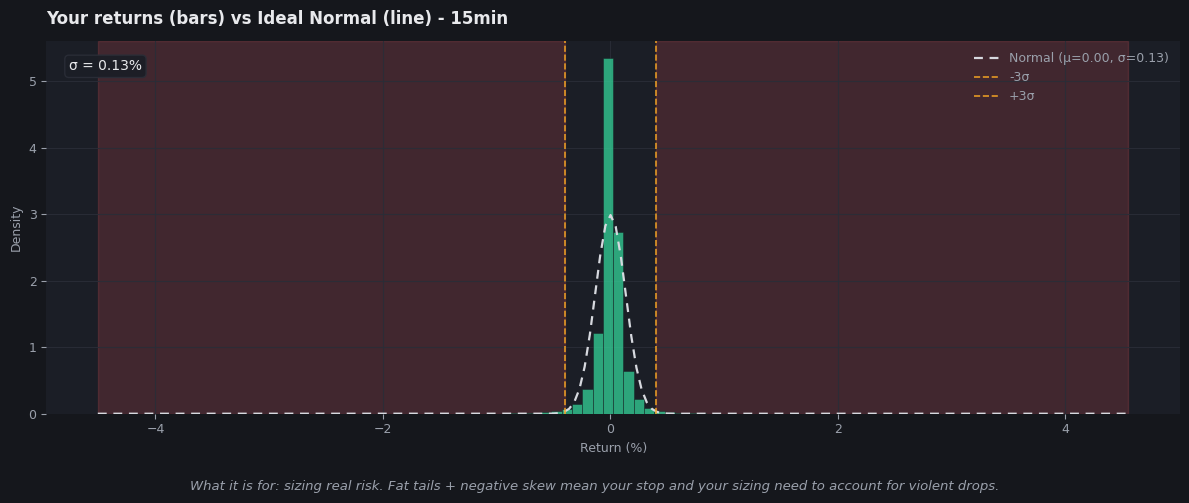


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.59x
Recent volatility (daily): 0.08%
Historical volatility (daily): 0.13%
Comes in waves? moderate


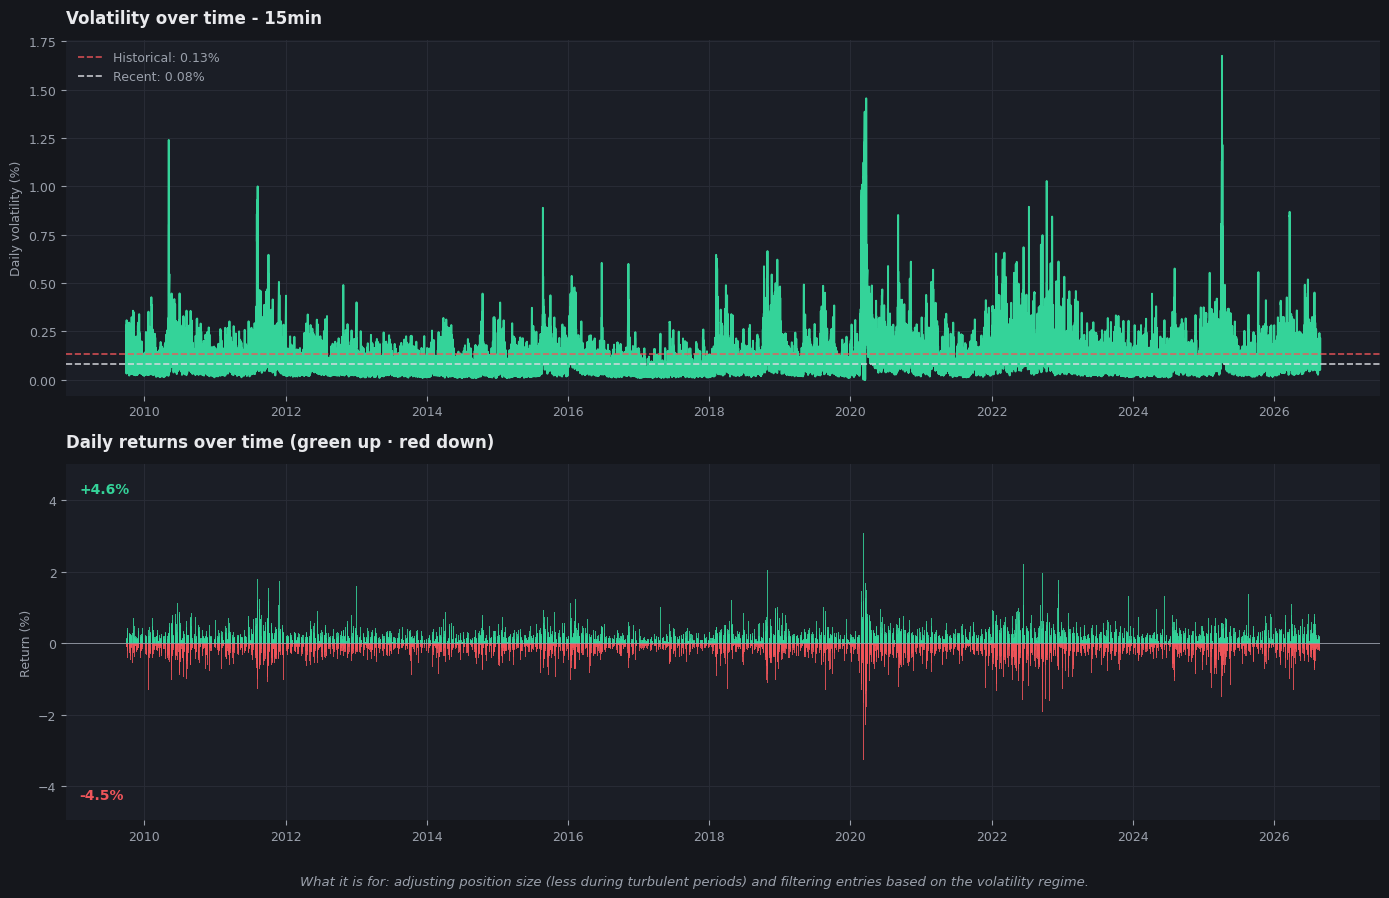


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.00 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: -0.00 reverts


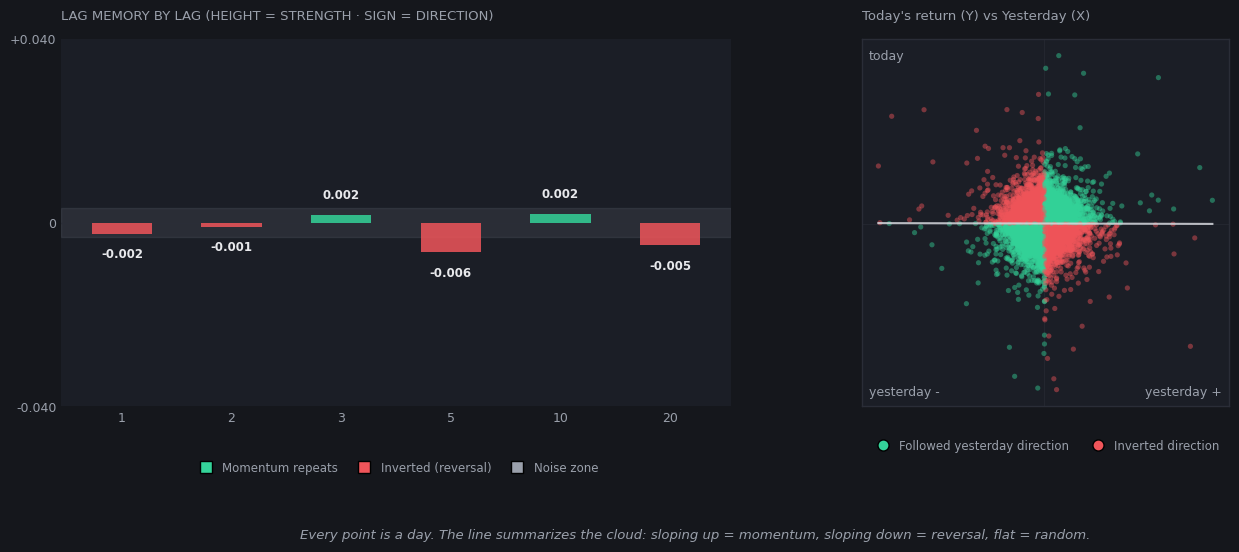


PATTERNS
SEASONALITY?


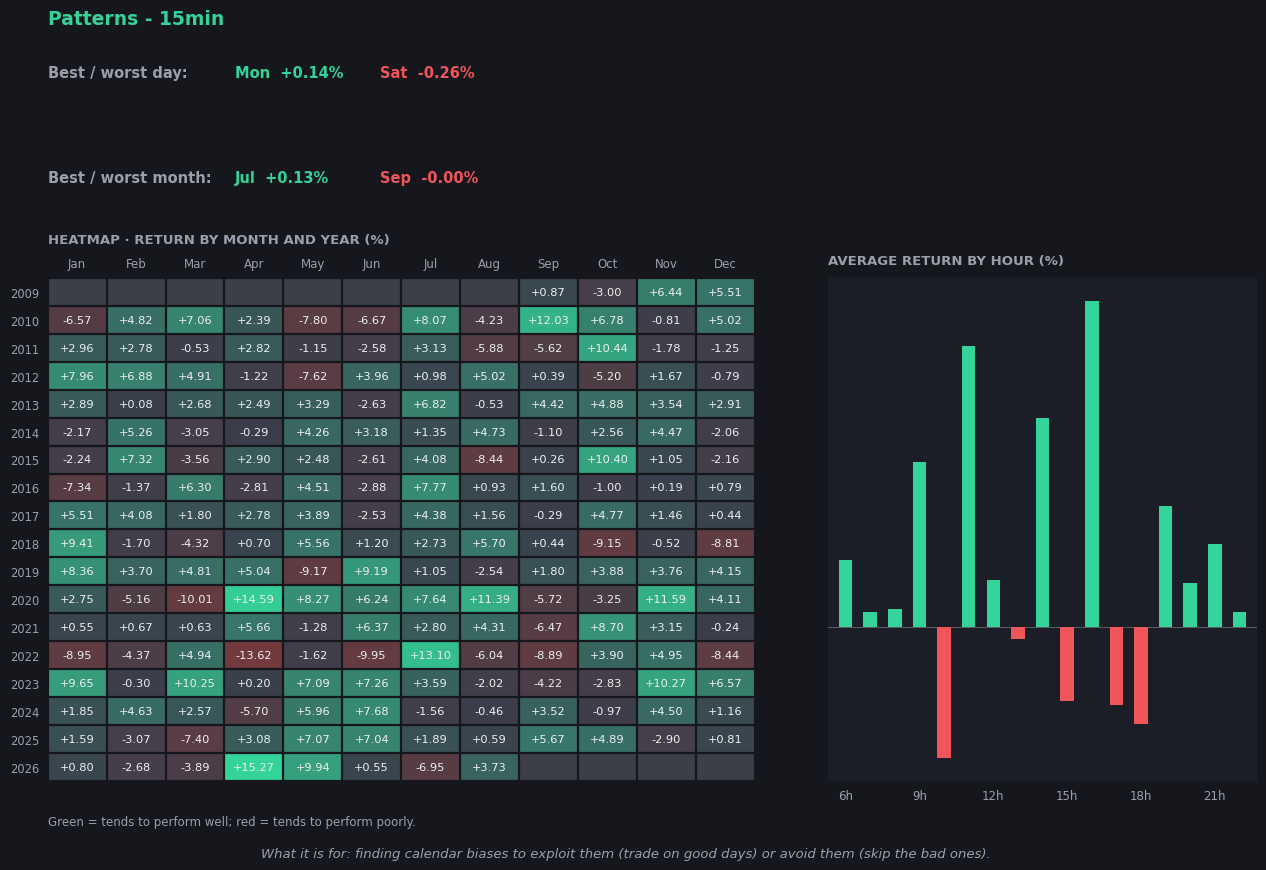


Average return by day of week (Mon-Fri, %):
Mon: 0.14%
Tue: 0.11%
Wed: 0.09%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.06%
Feb: 0.06%
Mar: 0.04%
Apr: 0.08%
May: 0.07%
Jun: 0.05%
Jul: 0.13%
Aug: 0.02%
Sep: -0.00%
Oct: 0.08%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: 0.00%
08:00: 0.00%
09:00: 0.00%
10:00: -0.00%
11:00: 0.00%
12:00: 0.00%
13:00: -0.00%
14:00: 0.00%
15:00: -0.00%
16:00: 0.00%
17:00: -0.00%
18:00: -0.00%
19:00: 0.00%
20:00: 0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


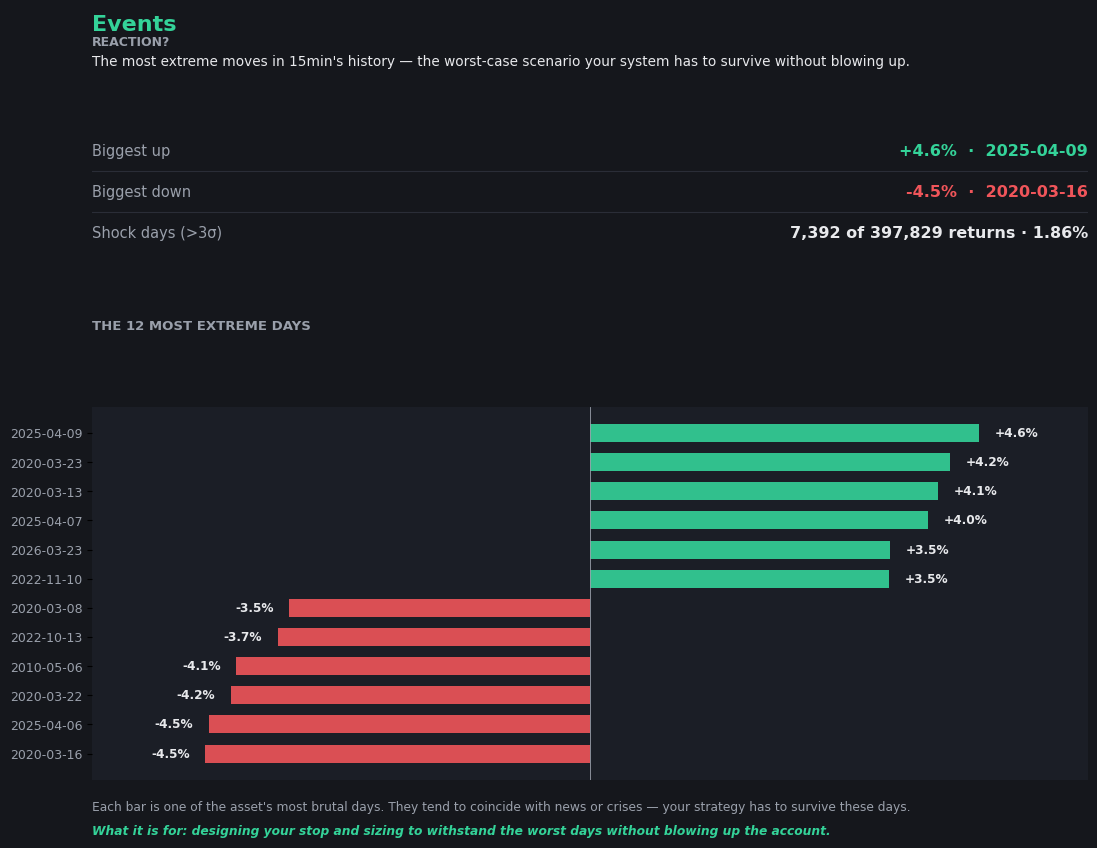

Biggest up: +4.6%
Biggest down: -4.5%
Shock days (>3σ): 7385 of 397,829 returns · 1.86%

Top 12 up days:
+4.6% - 2025-04-09
+4.2% - 2020-03-23
+4.1% - 2020-03-13
+4.0% - 2025-04-07
+3.5% - 2026-03-23
+3.5% - 2022-11-10

Top 12 down days:
-4.5% - 2020-03-16
-4.5% - 2025-04-06
-4.2% - 2020-03-22
-4.1% - 2010-05-06
-3.7% - 2022-10-13
-3.5% - 2020-03-08

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


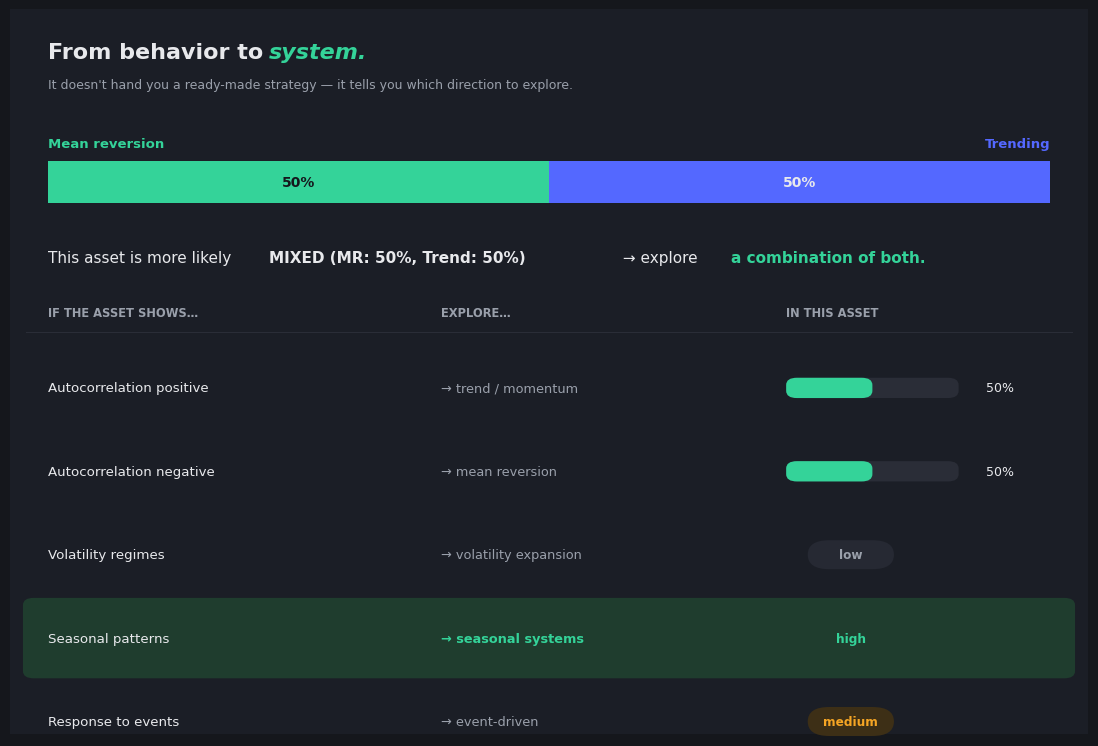


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 18.7%

Skewness
Which side the surprises lean toward. Negative means down moves are more violent than up moves.
→ -0.25 (left tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 58.73 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.002

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.494

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ moderate

Seasonality
Wh

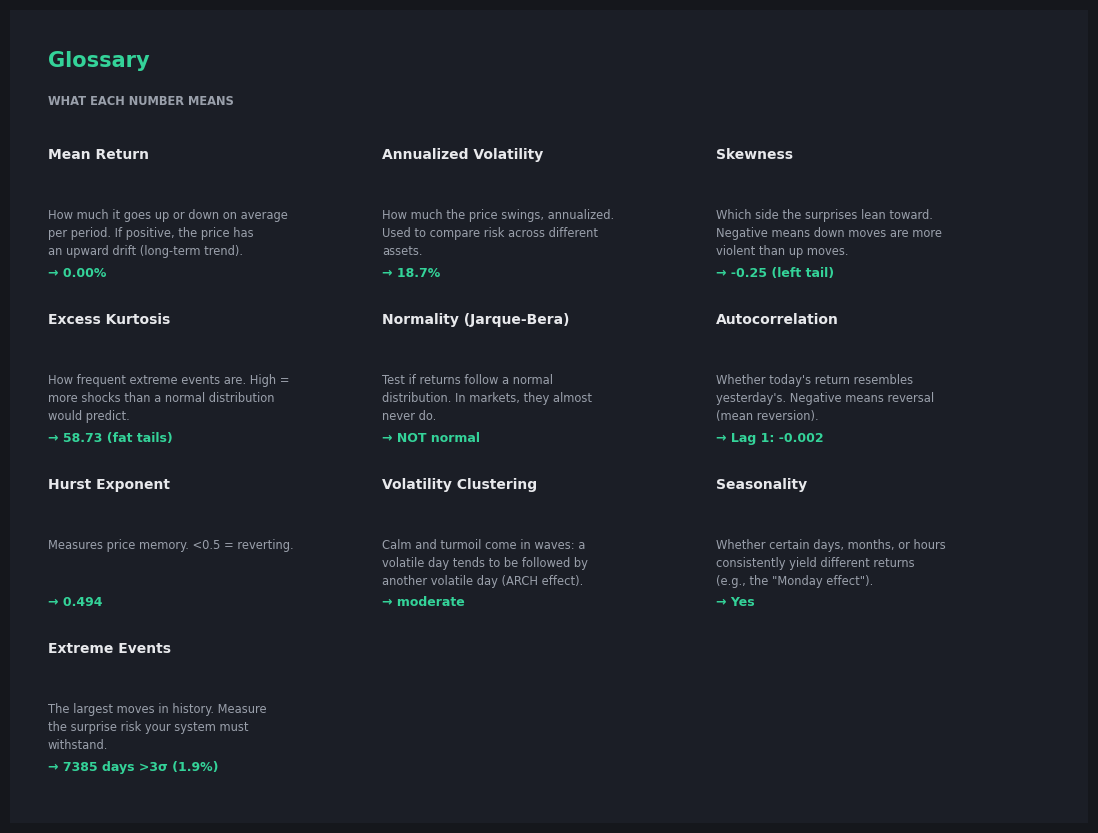




ANALYZING 1H TIMEFRAME

COMPLETE ANALYSIS: 1H
Bars: 101228
Period: 2009-09-27 18:00:00 → 2026-08-28 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.51
BULLISH
~18.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 18.7%
Skewness: -0.03 (symmetric)
Excess Kurtosis: 33.81 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 1952 (1.9%)


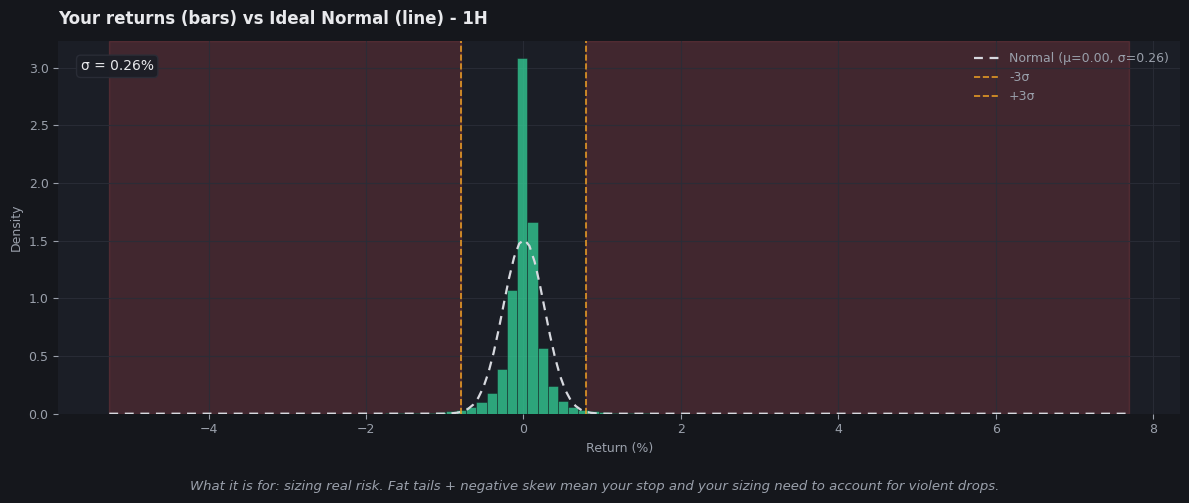


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.96x
Recent volatility (daily): 0.25%
Historical volatility (daily): 0.26%
Comes in waves? low


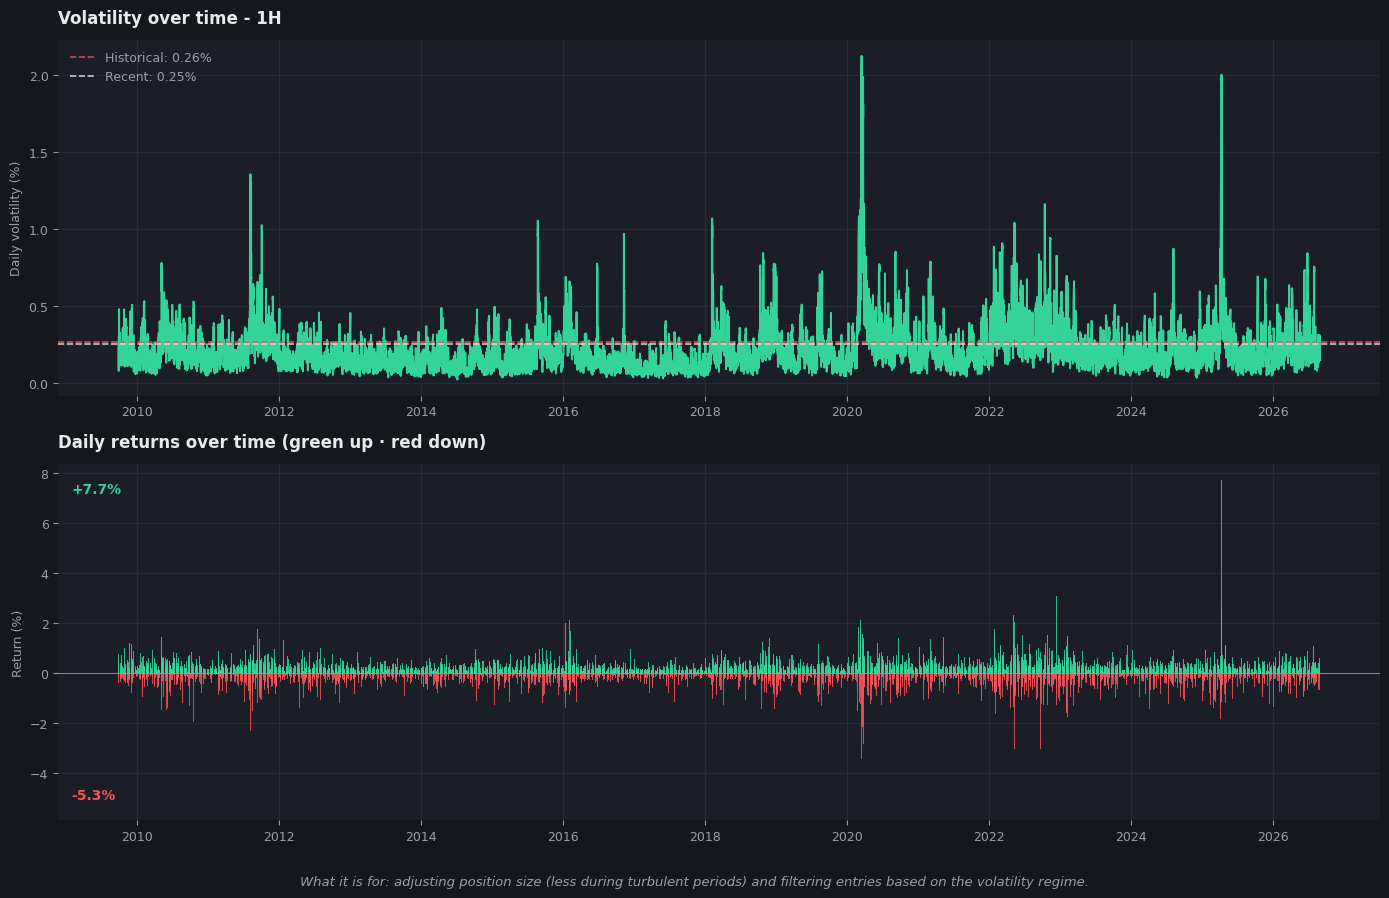


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.00 reverts
Lag 5 · vs 5 days ago: 0.00 ~0
Lag 20 · vs 20 days ago: 0.00 ~0


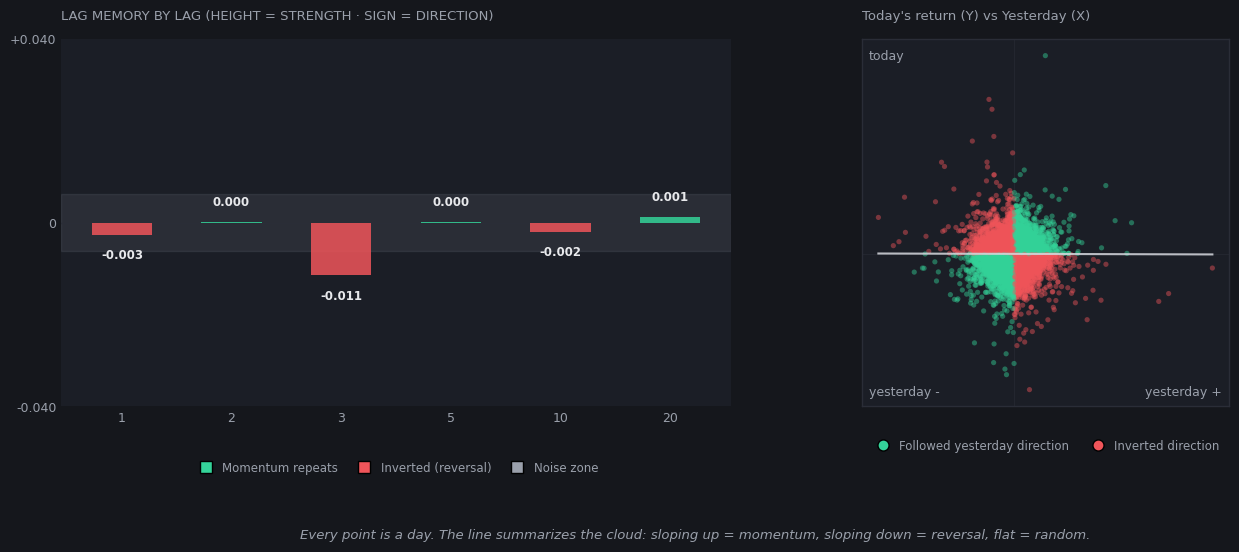


PATTERNS
SEASONALITY?


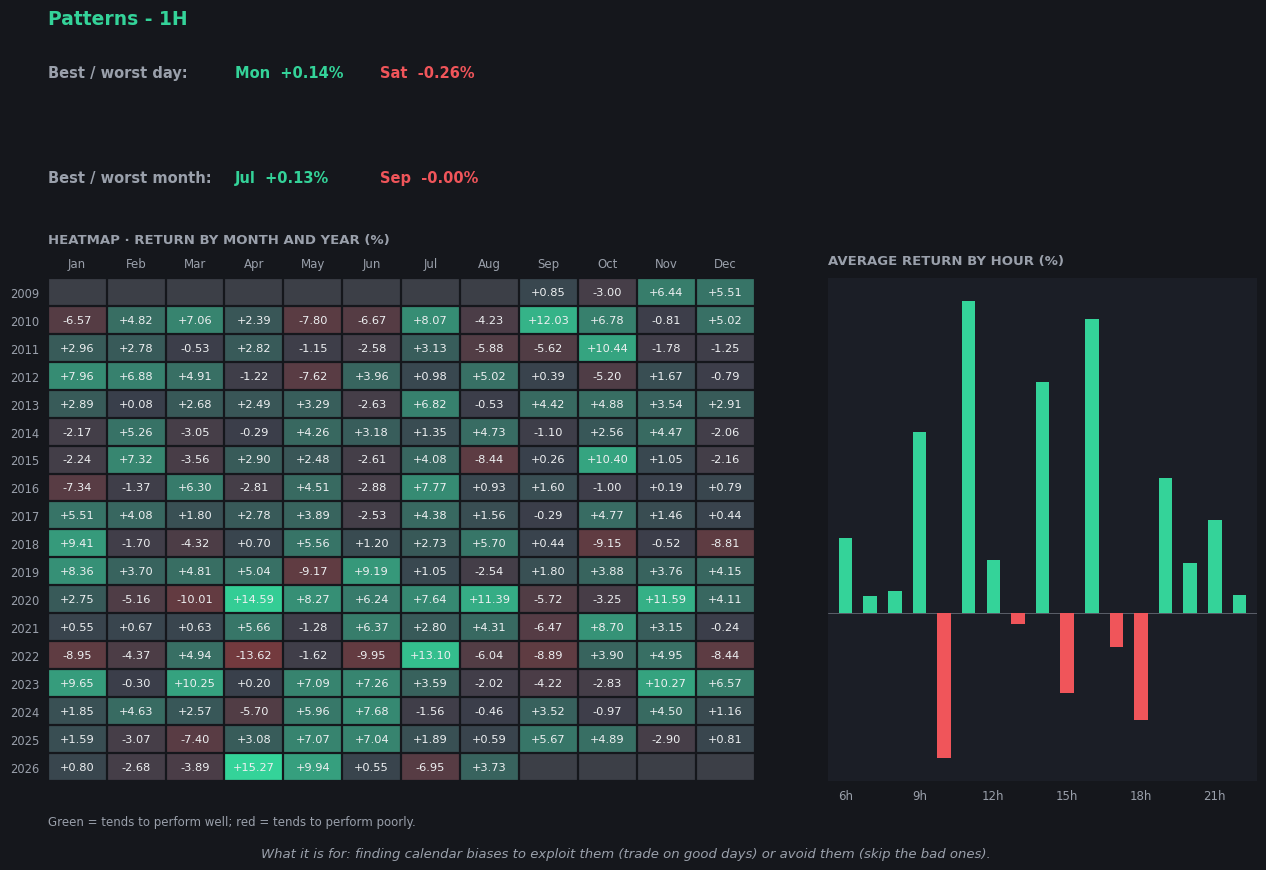


Average return by day of week (Mon-Fri, %):
Mon: 0.14%
Tue: 0.11%
Wed: 0.09%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.06%
Feb: 0.06%
Mar: 0.04%
Apr: 0.08%
May: 0.07%
Jun: 0.05%
Jul: 0.13%
Aug: 0.02%
Sep: -0.00%
Oct: 0.08%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
06:00: 0.00%
07:00: 0.00%
08:00: 0.00%
09:00: 0.01%
10:00: -0.01%
11:00: 0.01%
12:00: 0.00%
13:00: -0.00%
14:00: 0.01%
15:00: -0.00%
16:00: 0.01%
17:00: -0.00%
18:00: -0.00%
19:00: 0.01%
20:00: 0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


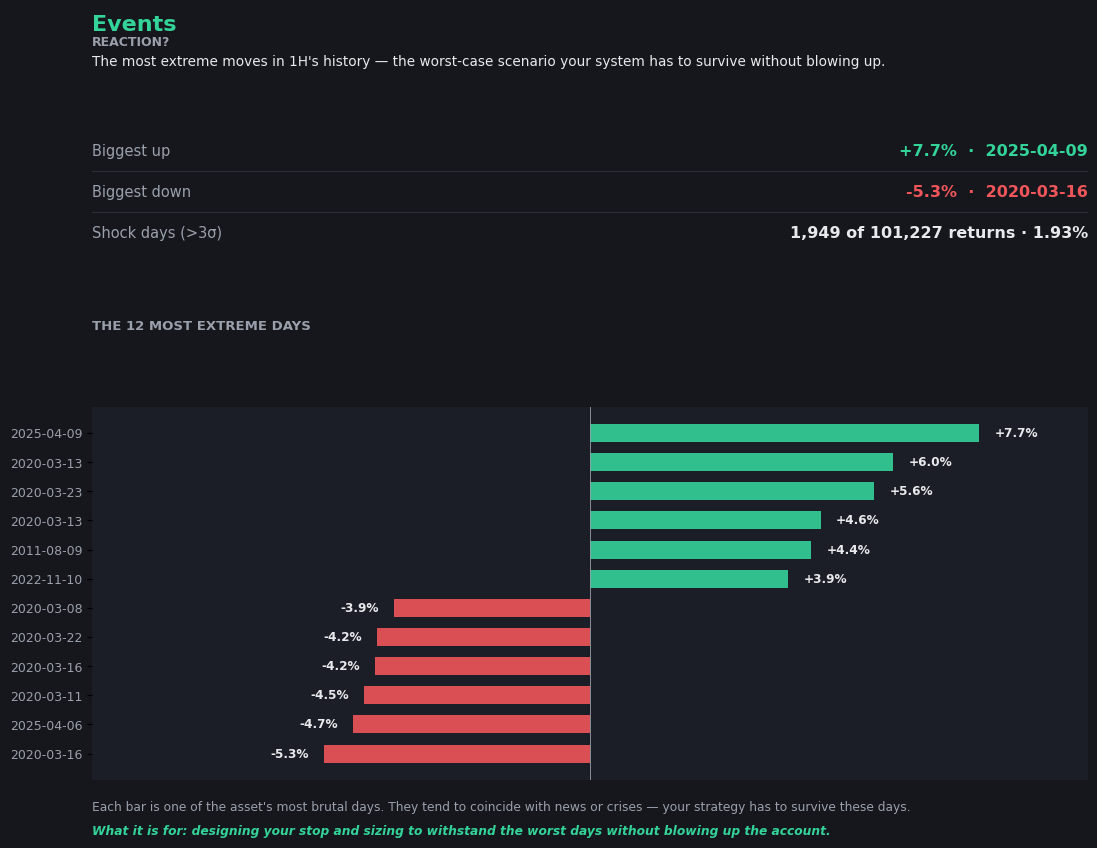

Biggest up: +7.7%
Biggest down: -5.3%
Shock days (>3σ): 1952 of 101,227 returns · 1.93%

Top 12 up days:
+7.7% - 2025-04-09
+6.0% - 2020-03-13
+5.6% - 2020-03-23
+4.6% - 2020-03-13
+4.4% - 2011-08-09
+3.9% - 2022-11-10

Top 12 down days:
-5.3% - 2020-03-16
-4.7% - 2025-04-06
-4.5% - 2020-03-11
-4.2% - 2020-03-16
-4.2% - 2020-03-22
-3.9% - 2020-03-08

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


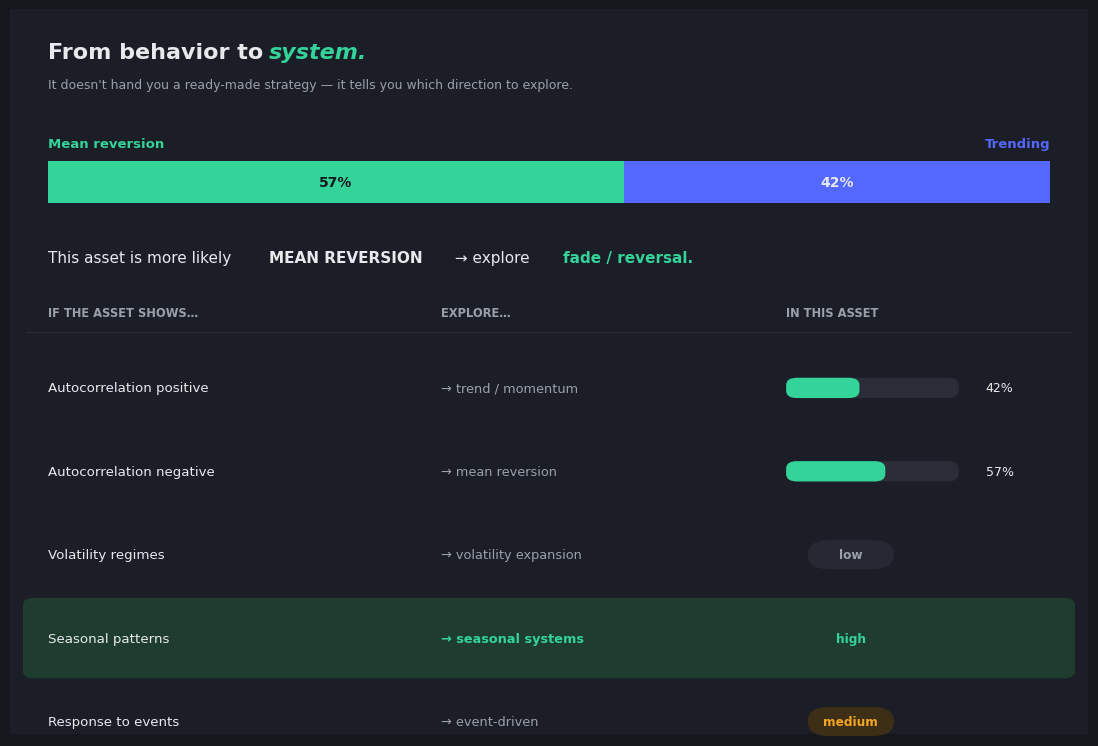


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 18.7%

Skewness
Which side the surprises lean toward. Negative means down moves are more violent than up moves.
→ -0.03 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 33.81 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.003

Hurst Exponent
Measures price memory. >0.5 = trending.
→ 0.513

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether 

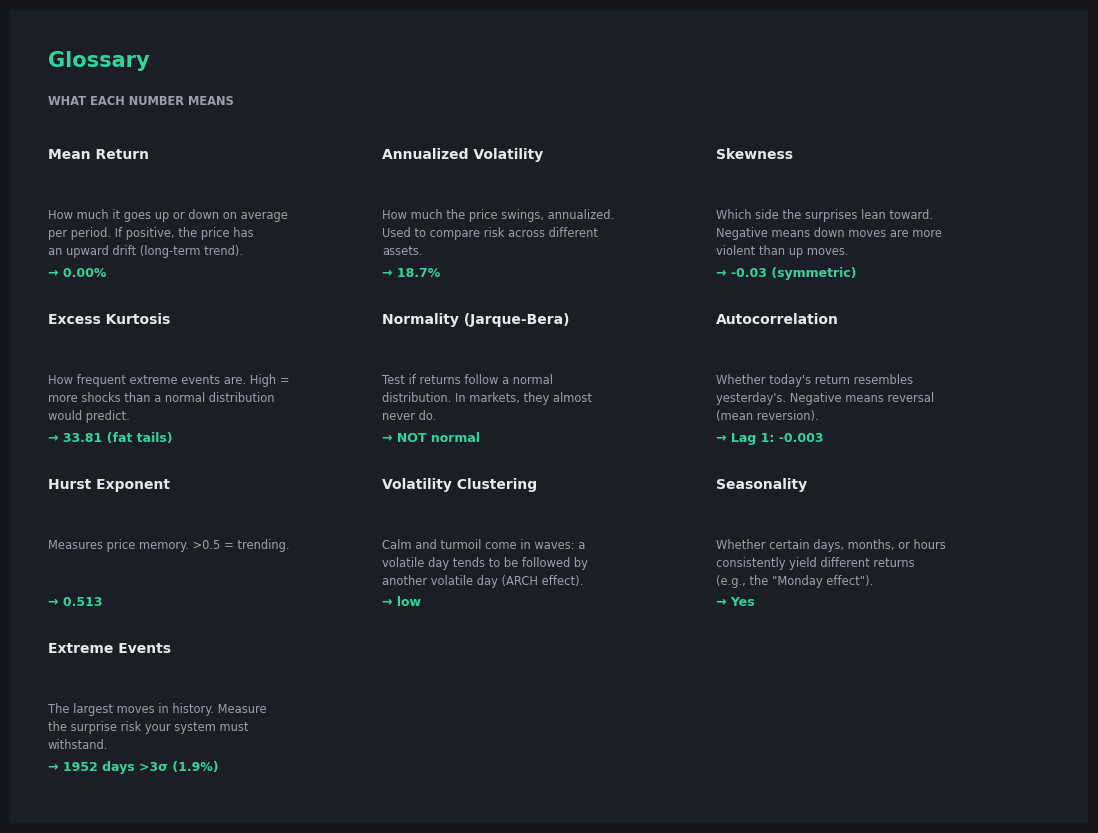




ANALYZING 4H TIMEFRAME

COMPLETE ANALYSIS: 4H
Bars: 27027
Period: 2009-09-27 16:00:00 → 2026-08-28 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.51
BULLISH
~18.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.01%
Annualized volatility: 18.7%
Skewness: 0.02 (symmetric)
Excess Kurtosis: 25.35 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 506 (1.9%)


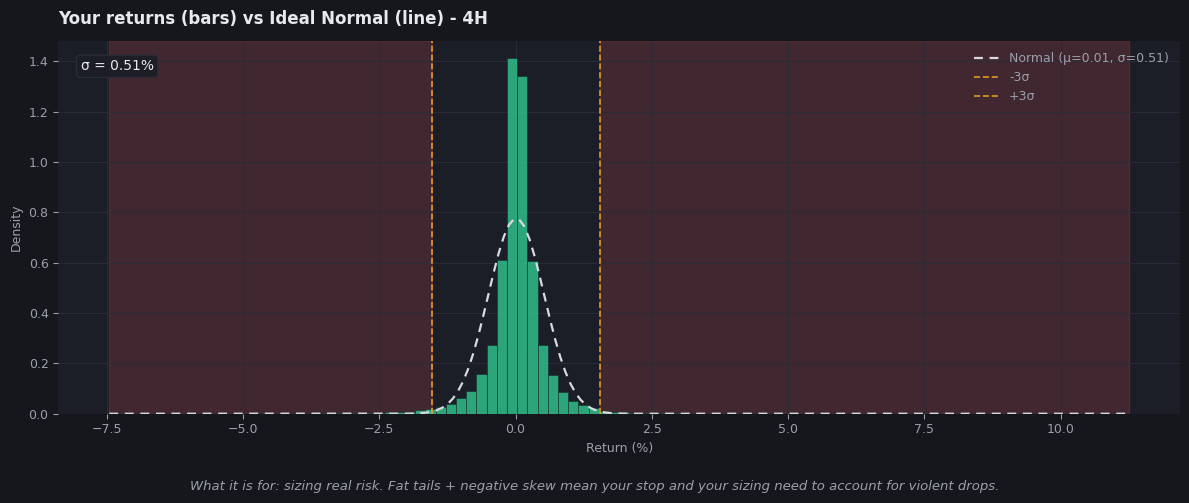


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.65x
Recent volatility (daily): 0.33%
Historical volatility (daily): 0.51%
Comes in waves? low


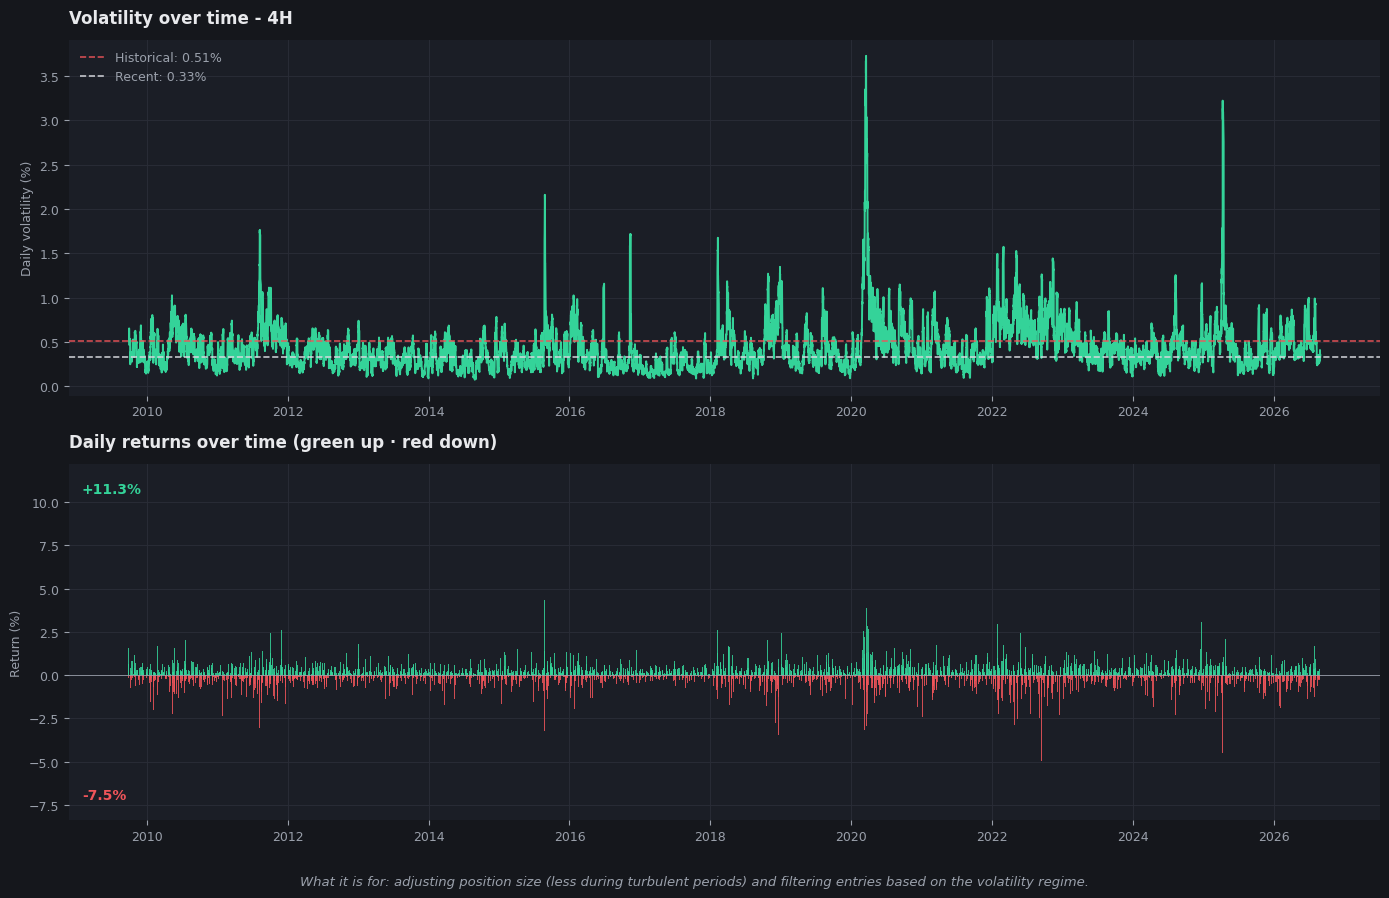


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


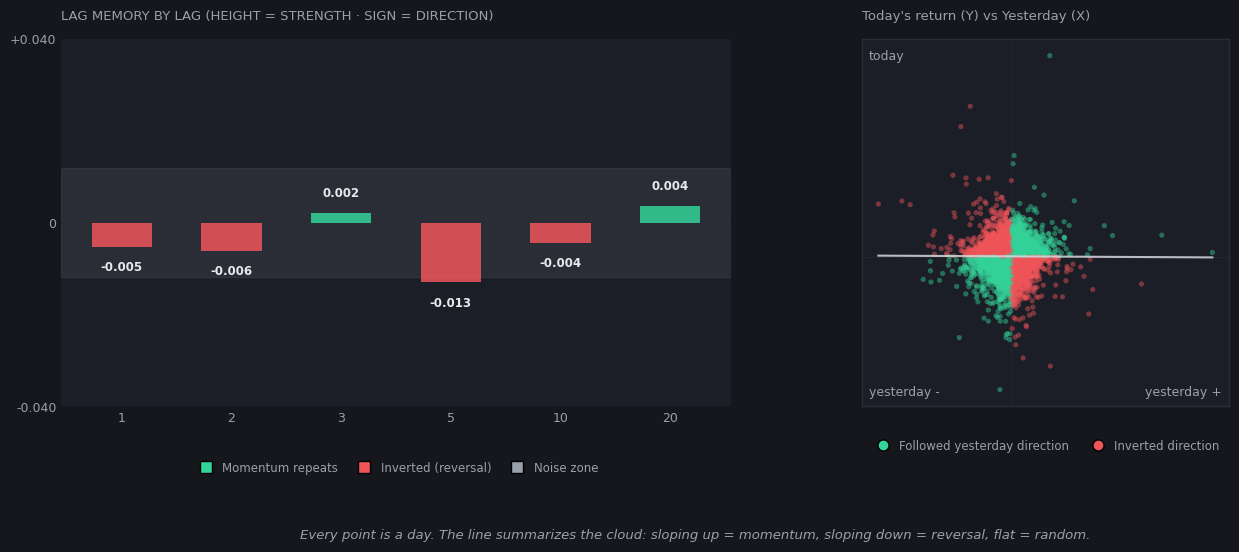


PATTERNS
SEASONALITY?


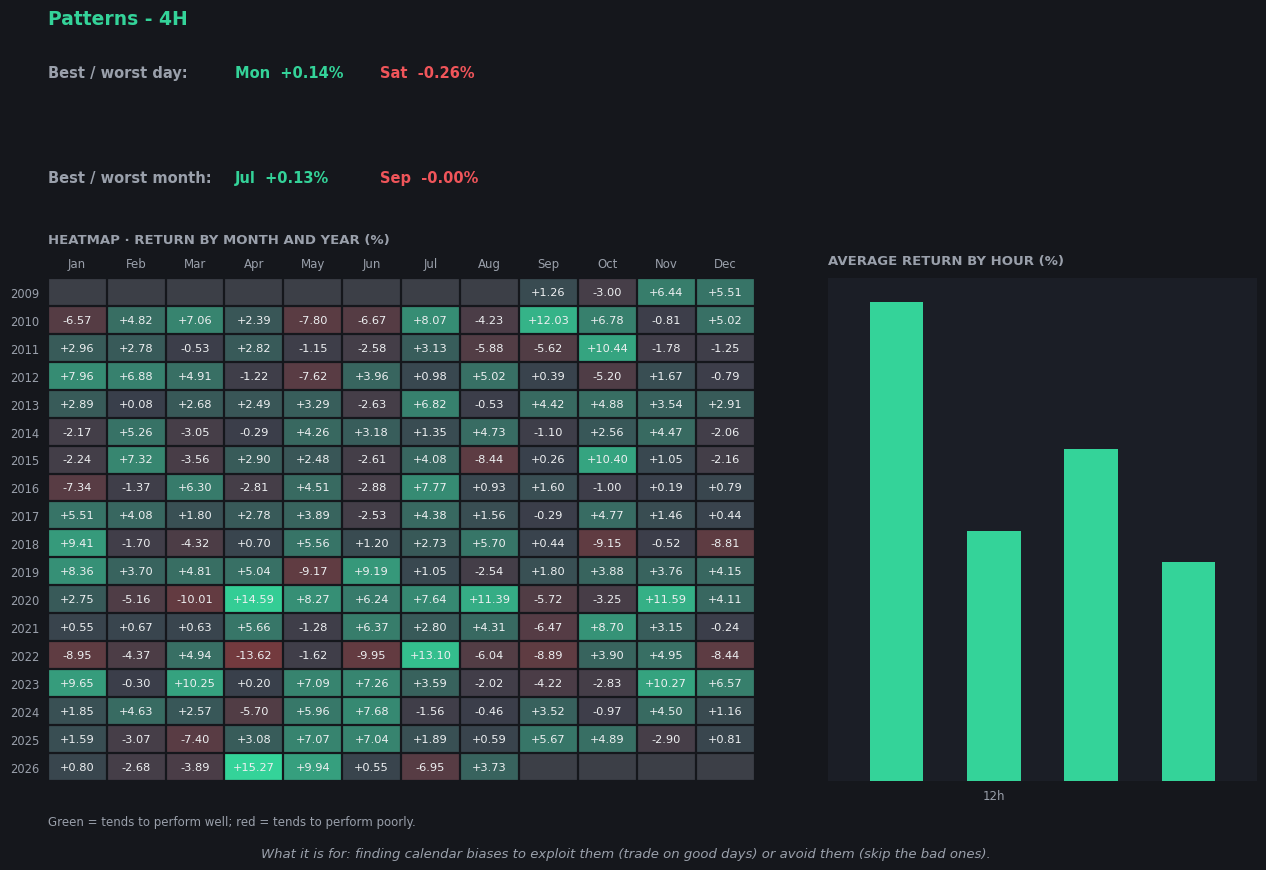


Average return by day of week (Mon-Fri, %):
Mon: 0.14%
Tue: 0.11%
Wed: 0.09%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.06%
Feb: 0.06%
Mar: 0.04%
Apr: 0.08%
May: 0.07%
Jun: 0.05%
Jul: 0.13%
Aug: 0.02%
Sep: -0.00%
Oct: 0.08%
Nov: 0.12%
Dec: 0.02%

Average return by hour (6:00-22:00, %):
08:00: 0.01%
12:00: 0.01%
16:00: 0.01%
20:00: 0.01%

EXTREME EVENTS
REACTION?


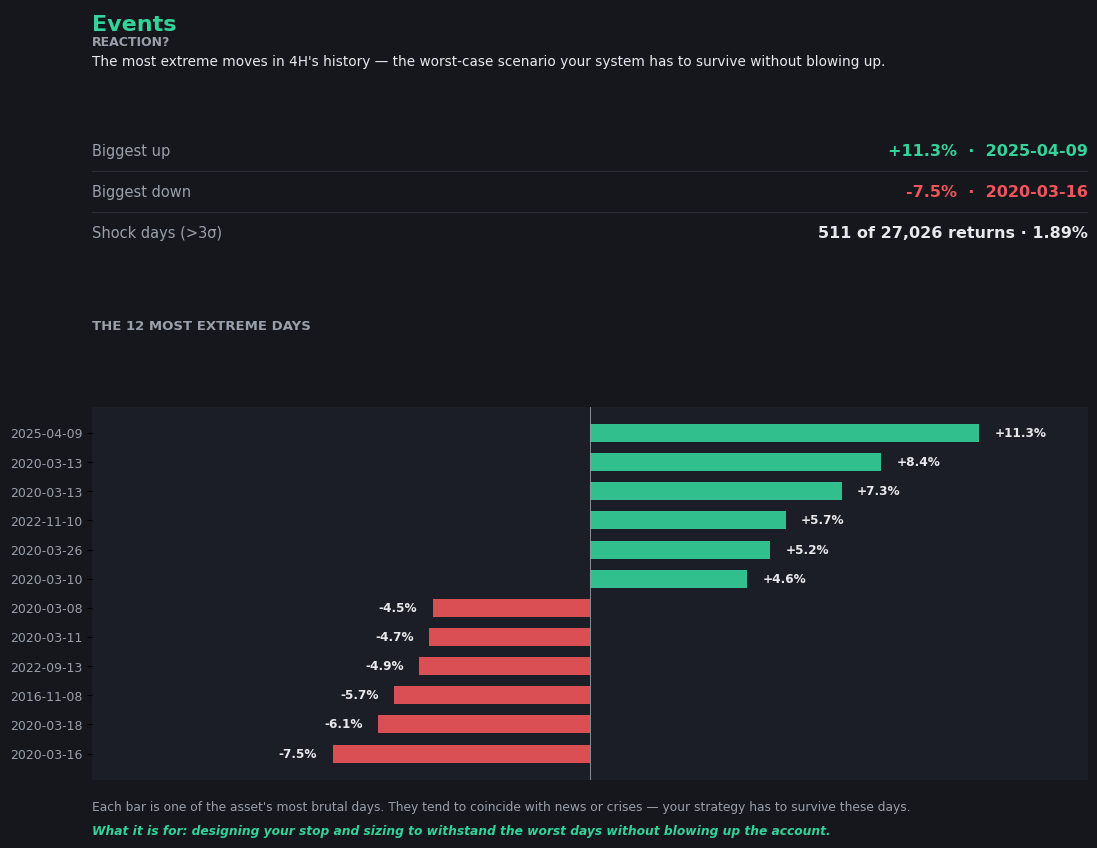

Biggest up: +11.3%
Biggest down: -7.5%
Shock days (>3σ): 506 of 27,026 returns · 1.87%

Top 12 up days:
+11.3% - 2025-04-09
+8.4% - 2020-03-13
+7.3% - 2020-03-13
+5.7% - 2022-11-10
+5.2% - 2020-03-26
+4.6% - 2020-03-10

Top 12 down days:
-7.5% - 2020-03-16
-6.1% - 2020-03-18
-5.7% - 2016-11-08
-4.9% - 2022-09-13
-4.7% - 2020-03-11
-4.5% - 2020-03-08

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


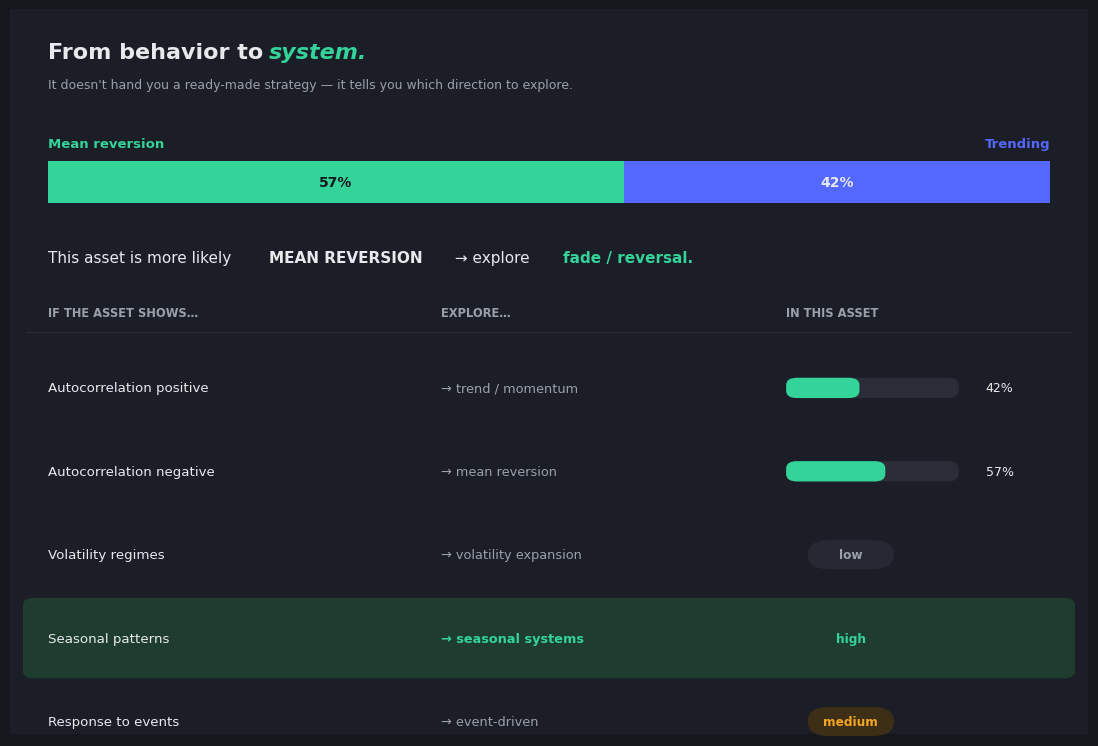


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.01%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 18.7%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.02 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 25.35 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.005

Hurst Exponent
Measures price memory. >0.5 = trending.
→ 0.506

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether c

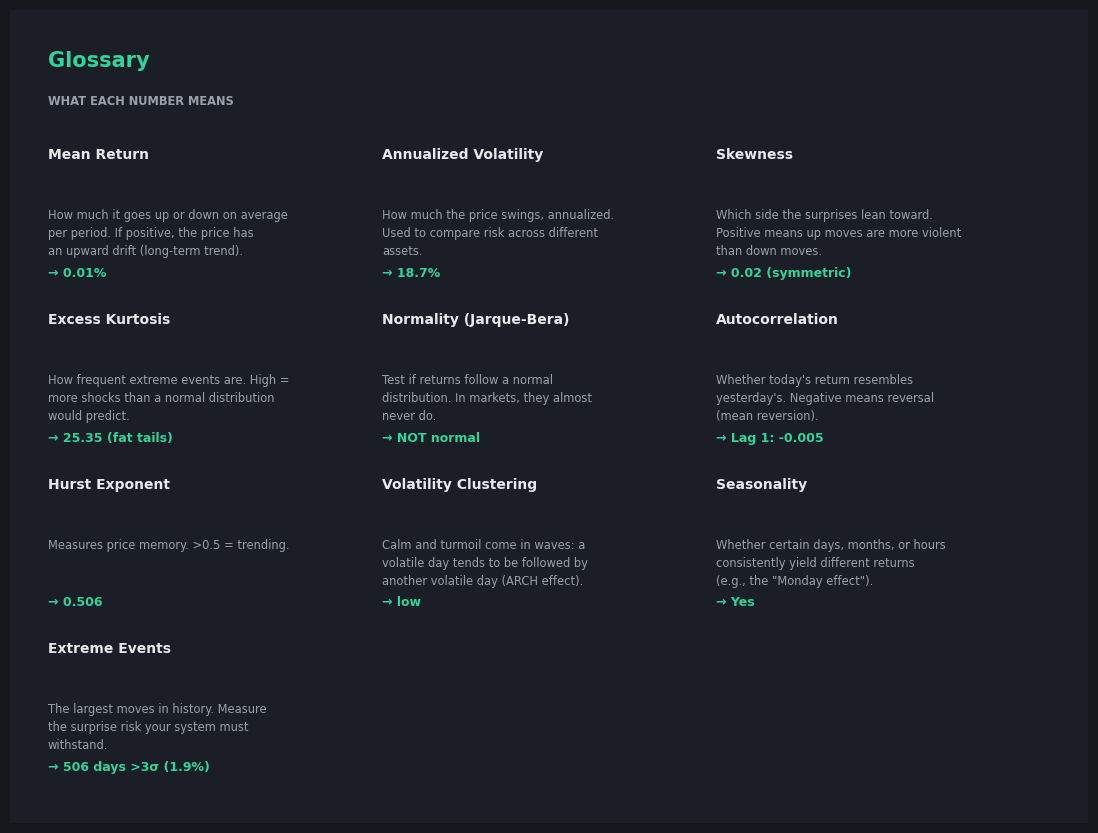




ANALYZING 1D TIMEFRAME

COMPLETE ANALYSIS: 1D
Bars: 5262
Period: 2009-09-27 00:00:00 → 2026-08-28 00:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.48
BULLISH
~18.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.06%
Annualized volatility: 18.7%
Skewness: 0.09 (symmetric)
Excess Kurtosis: 9.00 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 78 (1.5%)


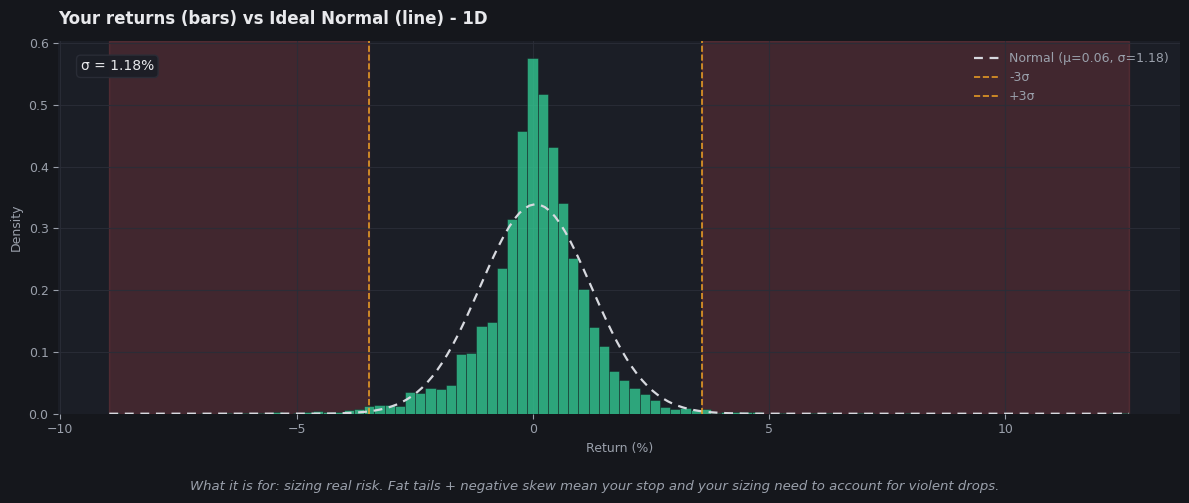


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.57x
Recent volatility (daily): 0.67%
Historical volatility (daily): 1.18%
Comes in waves? moderate


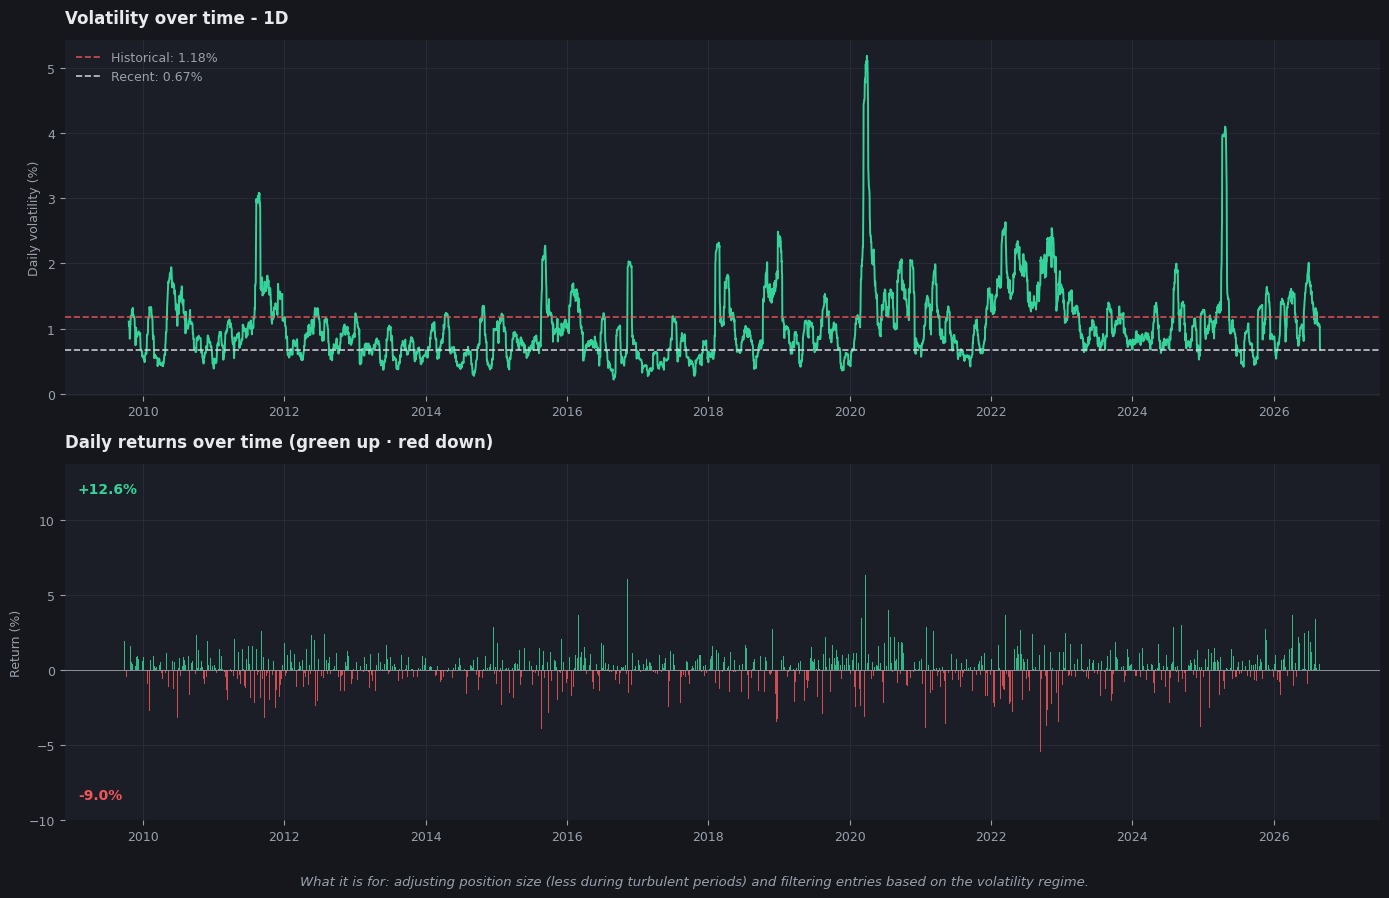


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.07 reverts
Lag 5 · vs 5 days ago: -0.00 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


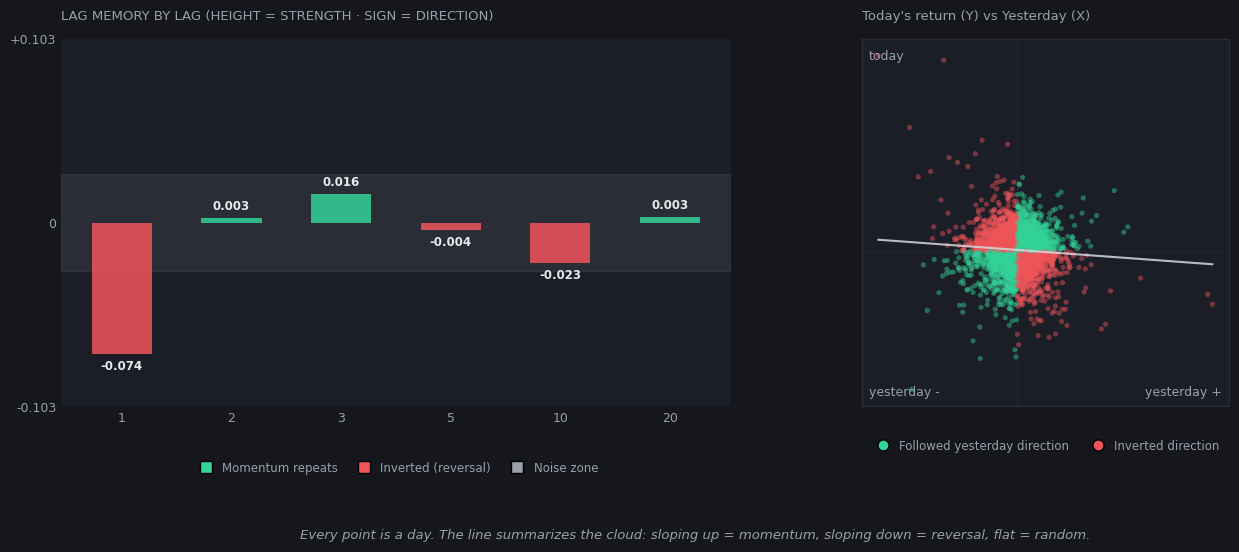


PATTERNS
SEASONALITY?


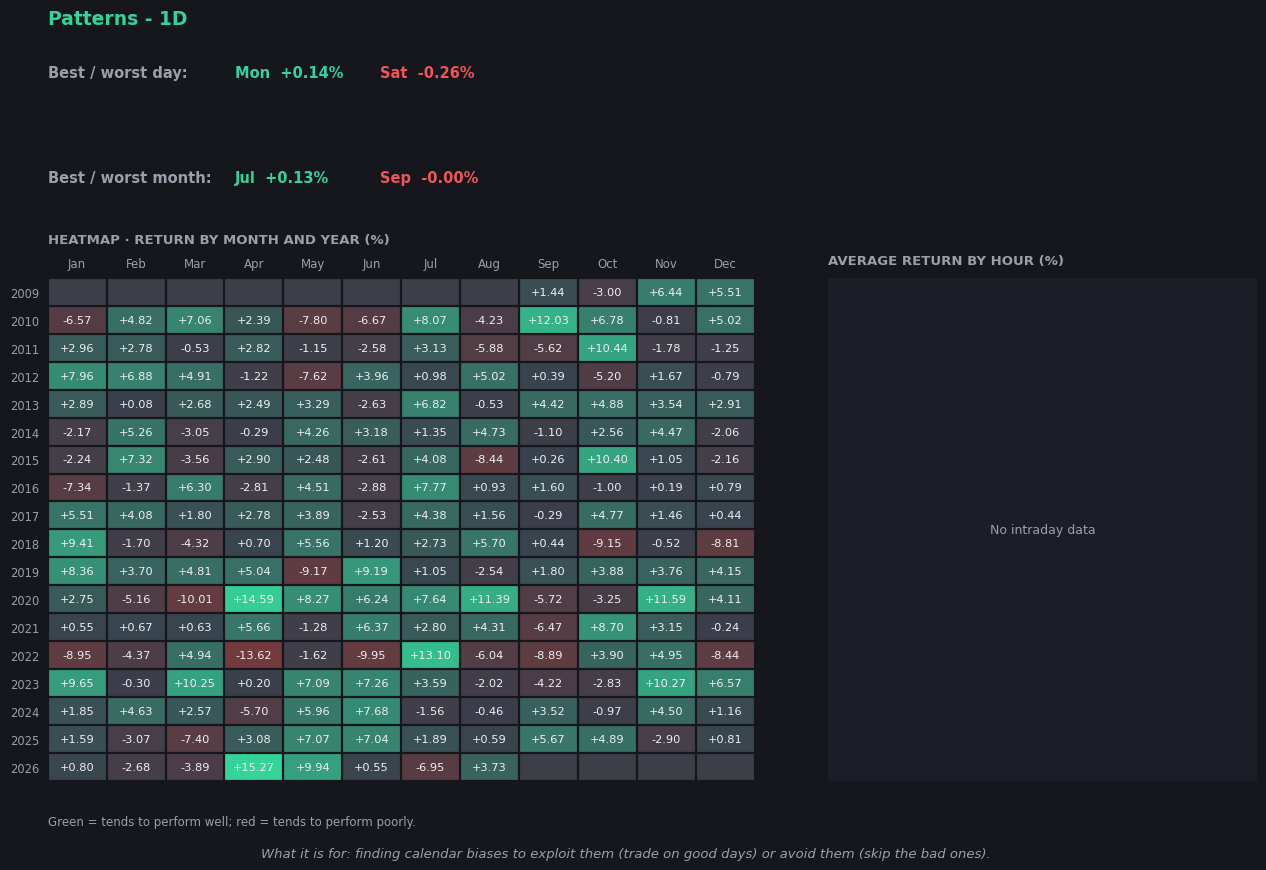


Average return by day of week (Mon-Fri, %):
Mon: 0.14%
Tue: 0.11%
Wed: 0.09%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.06%
Feb: 0.06%
Mar: 0.04%
Apr: 0.08%
May: 0.07%
Jun: 0.05%
Jul: 0.13%
Aug: 0.02%
Sep: -0.00%
Oct: 0.08%
Nov: 0.12%
Dec: 0.02%

EXTREME EVENTS
REACTION?


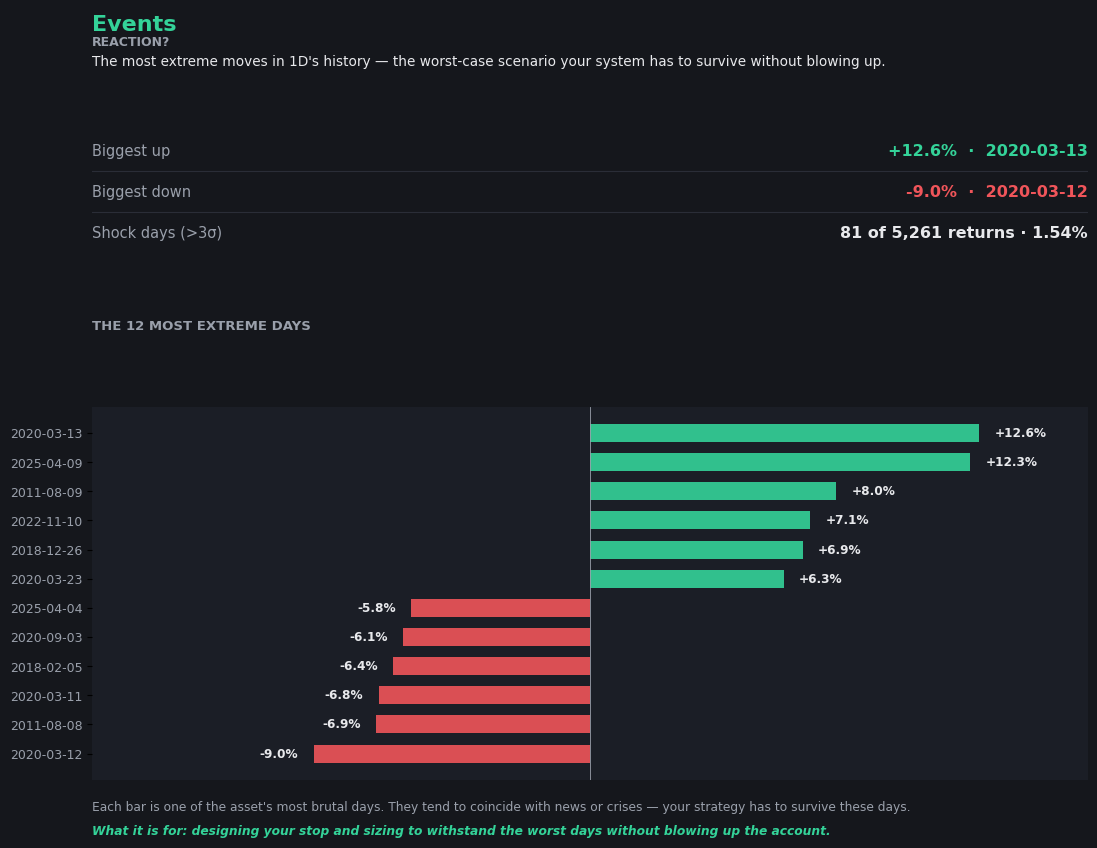

Biggest up: +12.6%
Biggest down: -9.0%
Shock days (>3σ): 78 of 5,261 returns · 1.48%

Top 12 up days:
+12.6% - 2020-03-13
+12.3% - 2025-04-09
+8.0% - 2011-08-09
+7.1% - 2022-11-10
+6.9% - 2018-12-26
+6.3% - 2020-03-23

Top 12 down days:
-9.0% - 2020-03-12
-6.9% - 2011-08-08
-6.8% - 2020-03-11
-6.4% - 2018-02-05
-6.1% - 2020-09-03
-5.8% - 2025-04-04

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation negative	→ mean reversion	57%
Volatility regimes	→ volatility expansion	high
Seasonal patterns	→ seasonal systems	high
Response to events	→ event-driven	medium


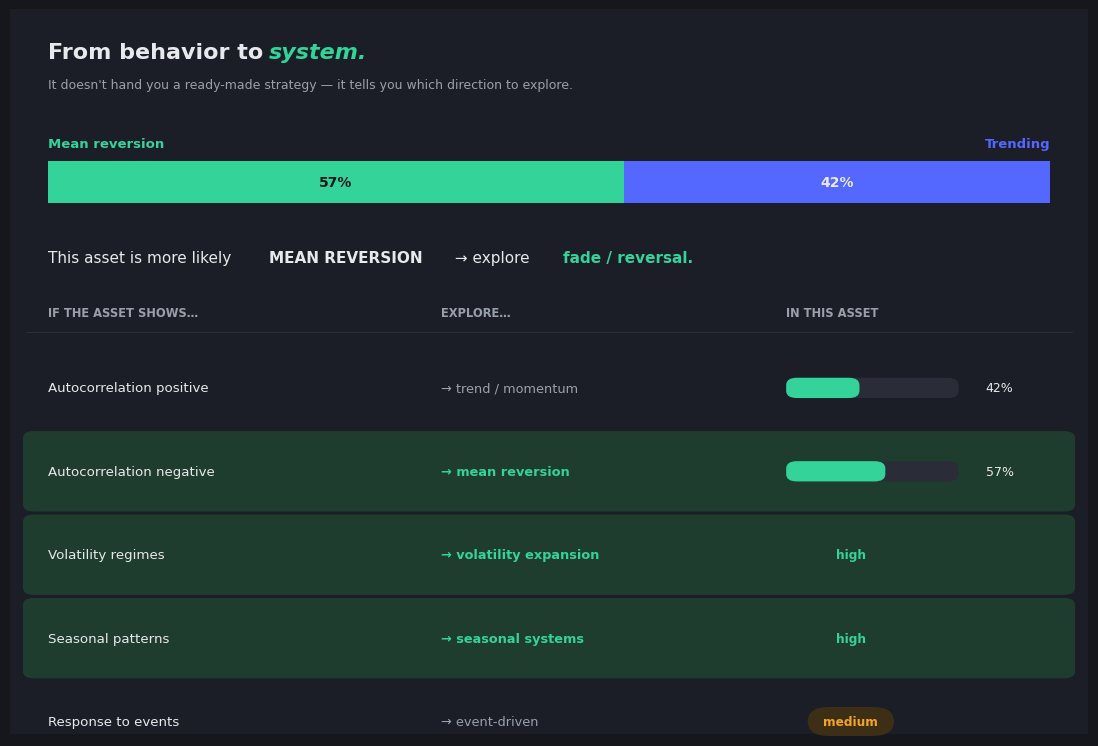


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ 0.06%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 18.7%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.09 (symmetric)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 9.00 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.074

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.480

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ moderate

Seasonality
Whet

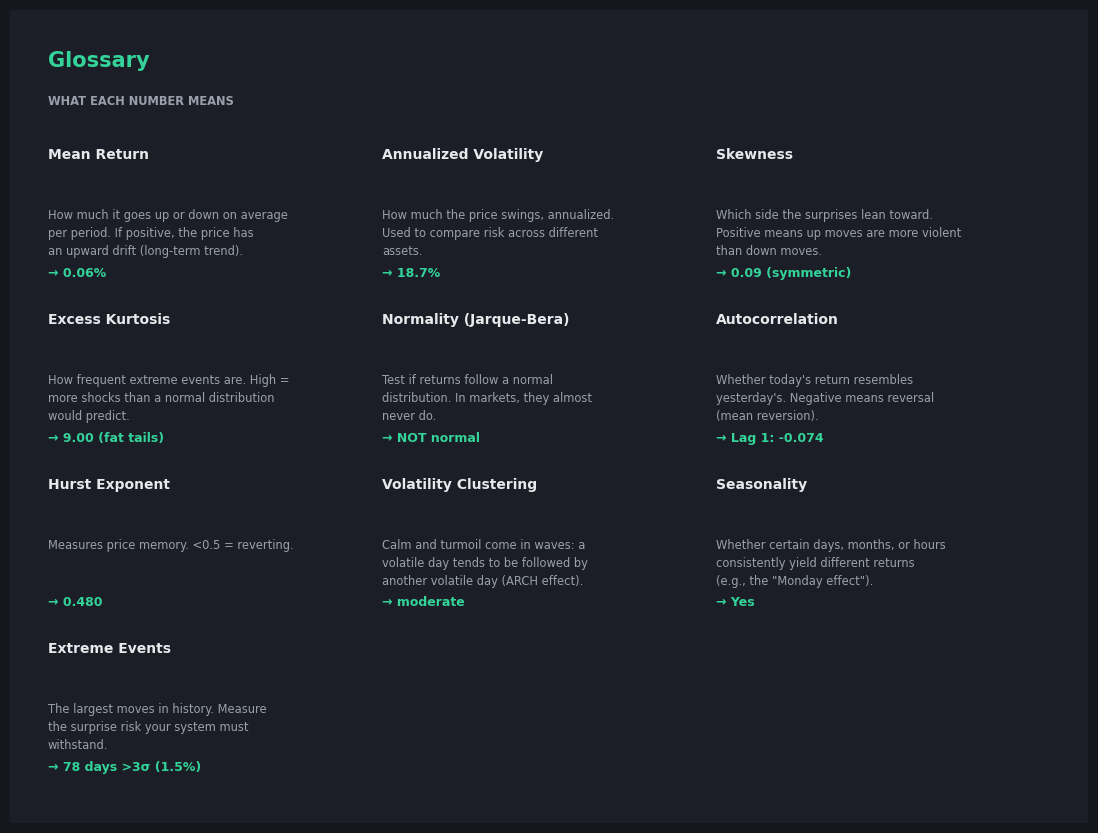




All timeframes analyzed successfully!


In [18]:
# Analyze 15min (raw data)
print("\n" + "="*70)
print("ANALYZING 15MIN TIMEFRAME")
print("="*70)
results_15min = analyze_timeframe_detailed(timeframes['15min'], '15min')

# Analyze 1H
print("\n" + "="*70)
print("ANALYZING 1H TIMEFRAME")
print("="*70)
results_1h = analyze_timeframe_detailed(timeframes['1H'], '1H')

# Analyze 4H
print("\n" + "="*70)
print("ANALYZING 4H TIMEFRAME")
print("="*70)
results_4h = analyze_timeframe_detailed(timeframes['4H'], '4H')

# Analyze 1D
print("\n" + "="*70)
print("ANALYZING 1D TIMEFRAME")
print("="*70)
results_1d = analyze_timeframe_detailed(timeframes['1D'], '1D')

print("\nAll timeframes analyzed successfully!")

## SUMMARY OF RESULTS

In [19]:
summary_df = pd.DataFrame([
    results_15min,
    results_1h,
    results_4h,
    results_1d
])

summary_df = summary_df.set_index('name')

print("\n" + "="*70)
print("SUMMARY OF KEY METRICS ACROSS TIMEFRAMES")
print("="*70)
print(summary_df[['mean_ret', 'vol_ann', 'skew', 'kurt', 'hurst', 'mr_pct', 'trend_pct']])

# Optional: Show full summary if you want all columns
print("\n" + "-"*70)
print("FULL SUMMARY (all metrics)")
print("-"*70)
print(summary_df)


SUMMARY OF KEY METRICS ACROSS TIMEFRAMES
       mean_ret    vol_ann      skew       kurt     hurst  mr_pct  trend_pct
name                                                                        
15min  0.000807  18.670784 -0.249162  58.732229  0.493553    50.0       50.0
1H     0.003168  18.670784 -0.034854  33.811864  0.512935    57.5       42.5
4H     0.011896  18.670784  0.018889  25.347521  0.505946    57.5       42.5
1D     0.061286  18.670784  0.094859   9.001982  0.479710    57.5       42.5

----------------------------------------------------------------------
FULL SUMMARY (all metrics)
----------------------------------------------------------------------
       mean_ret    vol_ann      skew       kurt      normal  pct_extreme  \
name                                                                       
15min  0.000807  18.670784 -0.249162  58.732229  NOT normal     1.856325   
1H     0.003168  18.670784 -0.034854  33.811864  NOT normal     1.928339   
4H     0.011896  18.67

# END OF ANALYSIS

In [20]:
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print("All plots and statistics have been generated.")
print("The reusable functions from utils.py made this analysis concise and portable.")
print("\nSummary of key findings by timeframe:")
print("-"*50)
for idx, row in summary_df.iterrows():
    print(f"{idx}:")
    print(f"  Hurst: {row['hurst']:.3f} → {'Mean Reversion' if row['hurst'] < 0.45 else 'Trending' if row['hurst'] > 0.55 else 'Random Walk'}")
    print(f"  System bias: {row['mr_pct']:.0f}% Mean Reversion / {row['trend_pct']:.0f}% Trending")
    print(f"  Volatility (ann): {row['vol_ann']:.1f}%")
    print(f"  Extreme events (>3σ): {row['pct_extreme']:.2f}% of days")
    print("-"*50)


ANALYSIS COMPLETE
All plots and statistics have been generated.
The reusable functions from utils.py made this analysis concise and portable.

Summary of key findings by timeframe:
--------------------------------------------------
15min:
  Hurst: 0.494 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 18.7%
  Extreme events (>3σ): 1.86% of days
--------------------------------------------------
1H:
  Hurst: 0.513 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 18.7%
  Extreme events (>3σ): 1.93% of days
--------------------------------------------------
4H:
  Hurst: 0.506 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 18.7%
  Extreme events (>3σ): 1.87% of days
--------------------------------------------------
1D:
  Hurst: 0.480 → Random Walk
  System bias: 57% Mean Reversion / 42% Trending
  Volatility (ann): 18.7%
  Extreme events (>3σ): 1.48% of days
---------------------------